# Grupo 7 — Clasificación de países según transición energética (Área: Energía)
**Machine Learning — Práctica 1 — Entregable 3: guía de código en Python (versión Jupyter Notebook)**
Universidad Nacional de Ingeniería — FIIS — Ciclo 2026-II · Profesor: Dr. Ing. Hilario Aradiel Castañeda

| Integrante | Correo |
|---|---|
| Crisostomo Cahuas, Gabriel Andre | gabriel.crisostomo.c@uni.pe |
| Curto Meneses, Alessandro del Piero | alessandro.curto.m@uni.pe |
| Rubio Zeta, Luis Miguel | luis.rubio.z@uni.pe |

**Pregunta de fondo:** ¿qué países están dejando atrás la electricidad fósil y cuáles no? Este notebook prepara los datos para que, más adelante, un clasificador ubique a cada país y año en una etapa de la transición energética: **inicial**, **intermedia** o **avanzada**.

Se sigue CRISP-ML(Q) (Studer et al., 2021, https://doi.org/10.48550/arXiv.2003.05155) **solo hasta la fase 3**:

| Fase | Qué se hace | Qué se obtiene |
|---|---|---|
| 1. Comprensión del negocio | Objetivos, regla de etiqueta y requisitos R1–R10 | `resultados/reportes/fase1_negocio.md` |
| 2. Comprensión de los datos | Recolección (BM + OWID), exploración y calidad por fuente | Figuras 1–5 y reportes `fase2_*` |
| 3. Preparación de los datos | Selección, limpieza, Hampel, imputación, etiqueta, predictores, partición | `datos/preparados/etapas_transicion_preparado.csv` |

**No hay fase de modelado:** no se entrena ni se ejecuta ningún algoritmo de aprendizaje automático.

> Este notebook tiene el mismo código que `main.py`, dividido en celdas para verlo paso a paso. **Cómo usarlo:** abrirlo en la carpeta del proyecto (junto a `main.py` y la carpeta `datos/`) y ejecutar *Kernel → Restart Kernel and Run All Cells*. Usa la copia local de `datos/crudos/`, así que no necesita Internet.

## Paso 0. Importación de librerías
Las mismas de `main.py` más `IPython.display`, que sirve para mostrar tablas, textos y figuras dentro del notebook.

In [1]:
# =============================================================================
# PASO 0. IMPORTACIÓN DE LIBRERÍAS
# =============================================================================
# --- Biblioteca estándar de Python (no requiere instalación) -----------------
import argparse                     # opciones de la línea de comandos (--descargar, --pais)
import io                           # leer en memoria el CSV descargado de OWID
import json                         # guardar el resumen de la fase 1 en formato JSON
import sys                          # código de salida del programa
import time                         # esperas entre reintentos de descarga
from dataclasses import dataclass, asdict   # agrupar los requisitos de calidad
from datetime import datetime, timezone     # fecha de descarga de los datos
from pathlib import Path            # rutas que funcionan en Windows, Linux y macOS

# --- Librerías externas (se instalan con: pip install -r requirements.txt) ---
import numpy as np                  # cálculo numérico: logaritmos, medianas, NaN
import pandas as pd                 # tablas de datos (DataFrame) y series de tiempo
import requests                     # descarga de datos por HTTP (API del BM y OWID)
import matplotlib                   # gráficos
matplotlib.use("Agg")               # dibuja sin abrir ventanas; las figuras se guardan en PNG
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch

# Solo para el notebook: mostrar tablas, Markdown e imágenes en pantalla
from IPython.display import display, Image, Markdown

## Paso 1. Parámetros del proyecto
Rutas, fuentes, periodo, variables y requisitos de calidad. En `main.py` las opciones `--descargar` y `--pais` se pasan por consola; aquí se cambian en la celda siguiente.

In [2]:
# Opciones de ejecución (equivalen a los argumentos de main.py)
DESCARGAR = False   # True: vuelve a descargar los datos del Banco Mundial y de OWID (requiere Internet)
PAIS_REF = "PER"    # país que se muestra en la figura 4 (código ISO3)

In [3]:
# =============================================================================
# PASO 1. PARÁMETROS DEL PROYECTO
# =============================================================================
# Carpeta del proyecto. En Jupyter no existe __file__, por eso se usa la
# carpeta actual (la carpeta donde está main.ipynb).
RAIZ = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
CARPETA_CRUDOS = RAIZ / "datos" / "crudos"          # datos tal como llegan de las fuentes
CARPETA_PREPARADOS = RAIZ / "datos" / "preparados"  # salida final de la fase 3
CARPETA_REPORTES = RAIZ / "resultados" / "reportes" # tablas CSV y reportes Markdown/JSON
CARPETA_FIGURAS = RAIZ / "resultados" / "figuras"   # gráficos PNG

# Direcciones de descarga
URL_API_BM = "https://api.worldbank.org/v2"
URL_OWID = "https://raw.githubusercontent.com/owid/energy-data/master/owid-energy-data.csv"
ESPERA_MAX_SEG = 90     # tiempo máximo de espera por cada solicitud HTTP
INTENTOS = 3            # reintentos si la conexión falla

# Periodo de estudio
ANIO_INICIO, ANIO_FIN = 2000, 2024

# Indicadores del Banco Mundial: código -> (nombre en el proyecto, descripción)
INDICADORES_BM = {
    "NY.GDP.PCAP.KD":       ("pib_pc", "PIB per cápita (US$ constantes de 2015)"),
    "SP.POP.TOTL":          ("poblacion", "Población total (habitantes)"),
    "SP.URB.TOTL.IN.ZS":    ("urbano_pct", "Población urbana (% del total)"),
    "NV.IND.TOTL.ZS":       ("industria_pct", "Industria, valor agregado (% del PIB)"),
    "EG.FEC.RNEW.ZS":       ("renovable_pct", "Energía renovable (% del consumo final de energía)"),
    "EG.ELC.ACCS.ZS":       ("electricidad_pct", "Acceso a la electricidad (% de la población)"),
    "EN.GHG.CO2.PC.CE.AR5": ("co2_pc", "Emisiones de CO2 per cápita (t CO2e por habitante)"),
    "EG.USE.PCAP.KG.OE":    ("energia_pc_bm", "Uso de energía (kg de petróleo equivalente per cápita)"),
    "EG.USE.COMM.FO.ZS":    ("fosil_pct", "Energía de combustibles fósiles (% del total)"),
    "EG.ELC.COAL.ZS":       ("carbon_elec_pct", "Electricidad generada con carbón (% del total)"),
}
# Columnas de OWID: nombre original -> (nombre en el proyecto, descripción)
COLUMNAS_OWID = {
    "low_carbon_share_elec":  ("baja_carbono_elec_pct", "Electricidad baja en carbono: renovable + nuclear (% de la generación)"),
    "renewables_share_elec":  ("renovable_elec_pct", "Electricidad renovable (% de la generación)"),
    "fossil_share_elec":      ("fosil_elec_pct", "Electricidad fósil (% de la generación)"),
    "hydro_share_elec":       ("hidro_elec_pct", "Electricidad hidroeléctrica (% de la generación)"),
    "coal_share_elec":        ("carbon_elec_owid_pct", "Electricidad con carbón según OWID (% de la generación)"),
    "carbon_intensity_elec":  ("intensidad_carbono_elec", "Intensidad de carbono de la electricidad (gCO2/kWh)"),
    "energy_per_capita":      ("energia_pc", "Consumo de energía primaria per cápita (kWh)"),
    "per_capita_electricity": ("consumo_elec_pc", "Generación eléctrica per cápita (kWh)"),
    "energy_per_gdp":         ("intensidad_energetica", "Energía primaria por unidad de PIB (kWh/US$)"),
    "population":             ("poblacion_owid", "Población según OWID (habitantes)"),
}
# Columnas adicionales de OWID que solo se usan en las figuras
COLUMNAS_OWID_FIGURAS = [
    "gas_share_elec", "solar_share_elec", "wind_share_elec", "electricity_generation",
    "fossil_electricity", "nuclear_electricity", "hydro_electricity", "solar_electricity",
    "wind_electricity", "other_renewable_electricity",
]
VARS_BM = [v[0] for v in INDICADORES_BM.values()]
VARS_OWID = [v[0] for v in COLUMNAS_OWID.values()]
DESCRIPCION = {**{v[0]: v[1] for v in INDICADORES_BM.values()},
               **{v[0]: v[1] for v in COLUMNAS_OWID.values()}}

# Papel de cada variable en el proyecto
ETIQUETA_BASE = ["baja_carbono_elec_pct", "electricidad_pct"]   # insumos de la regla de etiqueta
COVARIABLES = ["pib_pc", "poblacion", "urbano_pct", "industria_pct",
               "renovable_pct", "co2_pc", "energia_pc", "consumo_elec_pc"]
# Variables de la matriz eléctrica: describen casi lo mismo que la etiqueta. Si
# entraran como predictores, el futuro modelo "vería la respuesta" (fuga de
# información), por eso se excluyen del conjunto final.
FUGA = ["renovable_elec_pct", "fosil_elec_pct", "hidro_elec_pct",
        "carbon_elec_owid_pct", "intensidad_carbono_elec", "carbon_elec_pct"]


@dataclass(frozen=True)
class Requisitos:
    """Requisitos de calidad fijados en la fase 1 (se verifican en la fase 3)."""
    min_paises: int = 120            # R1: países mínimos en el conjunto final
    cobertura_etiqueta: float = 0.85 # R2: años con dato de electricidad baja en carbono
    max_faltantes_var: float = 25.0  # R3: % máximo de vacíos para usar una variable
    max_faltantes_pais: float = 0.40 # un país sale si le falta > 40 % de años en una variable
    umbral_intermedia: float = 30.0  # b >= 30 %  -> al menos etapa intermedia
    umbral_avanzada: float = 60.0    # b >= 60 %  -> candidata a etapa avanzada ...
    acceso_minimo: float = 90.0      # ... solo si el acceso a la electricidad es >= 90 %
    min_clase: float = 10.0          # R7: % mínimo de filas por etapa
    tolerancia_fuentes: float = 5.0  # diferencia aceptada entre BM y OWID (% o p.p.)


REQ = Requisitos()

# Filtro de Hampel (detección de atípicos) e imputación
VENTANA_HAMPEL = 5          # años de la ventana móvil centrada
K_HAMPEL = 3.0              # número de desviaciones robustas para marcar un valor
DESVIO_MIN_PCT = 10.0       # además, al menos 10 puntos porcentuales ...
DESVIO_MIN_NIVEL = np.log(1.2)  # ... o 20 % en variables de nivel
ANIOS_CHOQUE = (2009, 2020) # crisis financiera y pandemia: cambios reales, no errores
MAX_HUECO = 3               # años seguidos que se pueden rellenar por interpolación

# Partición temporal (solo se ETIQUETAN las filas; no se entrena nada)
CORTES = {"entrenamiento": (2004, 2015), "validacion": (2016, 2019), "prueba": (2020, 2024)}

# Traducción de regiones y grupos de ingreso del Banco Mundial
REGIONES = {
    "Sub-Saharan Africa": ("África subsahariana", "africa_subsahariana"),
    "Latin America & Caribbean": ("América Latina y el Caribe", "america_latina_caribe"),
    "North America": ("América del Norte", "america_norte"),
    "East Asia & Pacific": ("Asia oriental y el Pacífico", "asia_oriental_pacifico"),
    "South Asia": ("Asia meridional", "asia_sur"),
    "Europe & Central Asia": ("Europa y Asia central", "europa_asia_central"),
    "Middle East, North Africa, Afghanistan & Pakistan":
        ("Medio Oriente, norte de África, Afganistán y Pakistán", "medio_oriente_norte_africa"),
}
INGRESOS = {
    "High income": ("Ingreso alto", "alto"),
    "Upper middle income": ("Ingreso medio alto", "medio_alto"),
    "Lower middle income": ("Ingreso medio bajo", "medio_bajo"),
    "Low income": ("Ingreso bajo", "bajo"),
}

# Colores de las figuras (uno por etapa)
COLOR_ETAPA = {"inicial": "#d1495b", "intermedia": "#edae49", "avanzada": "#00798c"}
AZUL, GRIS = "#30638e", "#8d99ae"
plt.rcParams.update({
    "font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#dddddd", "grid.linewidth": 0.6, "savefig.dpi": 150,
})

## Paso 2. Funciones de apoyo
Mensajes de avance, creación de carpetas, guardado de figuras, tablas Markdown y la **regla de etiqueta** `asignar_etapa`, que se usa en las fases 1 y 3.

In [4]:
# =============================================================================
# PASO 2. FUNCIONES DE APOYO
# =============================================================================
def seccion(texto: str) -> None:
    """Imprime un título de sección para seguir el avance en la consola."""
    print("\n" + "=" * 78 + f"\n {texto}\n" + "=" * 78)


def nota(texto: str) -> None:
    """Imprime un mensaje de avance con sangría."""
    print(f"   - {texto}")


def preparar_carpetas() -> None:
    """Crea las carpetas de salida si todavía no existen."""
    for carpeta in (CARPETA_CRUDOS, CARPETA_PREPARADOS, CARPETA_REPORTES, CARPETA_FIGURAS):
        carpeta.mkdir(parents=True, exist_ok=True)


def guardar_figura(fig, nombre: str) -> None:
    """Guarda una figura en resultados/figuras y libera la memoria."""
    fig.tight_layout()
    fig.savefig(CARPETA_FIGURAS / nombre, bbox_inches="tight")
    plt.close(fig)
    nota(f"figura guardada: resultados/figuras/{nombre}")


def tabla_md(df: pd.DataFrame) -> str:
    """Convierte un DataFrame en una tabla Markdown (sin depender de 'tabulate')."""
    columnas = [str(c) for c in df.columns]
    filas = ["| " + " | ".join(columnas) + " |", "|" + "---|" * len(columnas)]
    for _, fila in df.iterrows():
        filas.append("| " + " | ".join(str(v) for v in fila.values) + " |")
    return "\n".join(filas)


def es_porcentaje(variable: str) -> bool:
    """Las variables que terminan en _pct están acotadas entre 0 y 100."""
    return variable.endswith("_pct")

In [5]:
def asignar_etapa(b: float, acceso: float) -> str | float:
    """
    REGLA DE ETIQUETA (definida en la fase 1).
        b      = electricidad baja en carbono, promedio de 3 años (%)
        acceso = población con acceso a la electricidad (%)
    Avanzada   : b >= 60 y acceso >= 90
    Intermedia : b >= 30 (y no cumple la condición de avanzada)
    Inicial    : b < 30
    Devuelve NaN si todavía no hay tres años para promediar.
    """
    if pd.isna(b):
        return np.nan
    if b >= REQ.umbral_avanzada and acceso >= REQ.acceso_minimo:
        return "avanzada"
    return "intermedia" if b >= REQ.umbral_intermedia else "inicial"


# Prueba rápida de la regla con tres casos
for b, a in [(20, 100), (70, 60), (80, 99)]:
    print(f"b = {b} %, acceso = {a} %  ->  {asignar_etapa(b, a)}")

b = 20 %, acceso = 100 %  ->  inicial
b = 70 %, acceso = 60 %  ->  intermedia
b = 80 %, acceso = 99 %  ->  avanzada


In [6]:
# Crea datos/crudos, datos/preparados, resultados/reportes y resultados/figuras
preparar_carpetas()

## Paso 3. Fase 1 — Comprensión del negocio
Se fija el problema, el objetivo de negocio, el objetivo de minería de datos, los criterios de éxito, la regla de etiqueta y los requisitos R1–R10. Todavía no se usan datos.

**Resultado esperado:** `resultados/reportes/fase1_negocio.json` y `fase1_negocio.md`.

In [7]:
# =============================================================================
# PASO 3. FASE 1 - COMPRENSIÓN DEL NEGOCIO
# =============================================================================
def fase1_comprension_negocio() -> dict:
    """
    Deja por escrito QUÉ se quiere resolver, PARA QUIÉN y CÓMO se sabrá que la
    preparación de datos fue correcta. No usa datos todavía.

    Resultado esperado:
      * resultados/reportes/fase1_negocio.json y fase1_negocio.md con los
        objetivos, la regla de etiqueta y los requisitos R1-R10.
    """
    seccion("FASE 1 - COMPRENSIÓN DEL NEGOCIO")
    negocio = {
        "problema": ("Los organismos que financian o planifican la transición energética "
                     "necesitan saber, cada año y con un criterio común, en qué etapa está "
                     "cada país para priorizar recursos y cooperación."),
        "interesados": ["Ministerios de energía (en el Perú, el MINEM)", "Bancos de desarrollo",
                        "Investigadores y organismos internacionales"],
        "objetivo_negocio": ("Disponer cada año de una clasificación comparable de los países "
                             "según su avance en la transición energética."),
        "objetivo_mineria_datos": ("Preparar un conjunto país-año con la etapa de transición "
                                   "(inicial, intermedia, avanzada) como variable objetivo y "
                                   "predictores medidos el año anterior, apto para entrenar "
                                   "después un clasificador de tres clases."),
        "criterio_exito_modelo_futuro": "Exactitud balanceada >= 0,75 en los años de prueba (2020-2024).",
        "criterio_exito_negocio": "Cada clasificación debe poder explicarse con una regla pública.",
        "regla_etiqueta": {
            "b": "promedio de 3 años de la electricidad baja en carbono (% de la generación)",
            "avanzada": f"b >= {REQ.umbral_avanzada:.0f} y acceso >= {REQ.acceso_minimo:.0f}",
            "intermedia": f"b >= {REQ.umbral_intermedia:.0f} (sin cumplir avanzada)",
            "inicial": f"b < {REQ.umbral_intermedia:.0f}",
            "base": "ODS 7: electricidad limpia (7.2) y acceso universal (7.1)",
        },
        "requisitos": {
            "R1": f"Al menos {REQ.min_paises} países en el conjunto final",
            "R2": f"b disponible en >= {REQ.cobertura_etiqueta:.0%} de los años de cada país",
            "R3": f"Variables usadas con <= {REQ.max_faltantes_var:.0f} % de faltantes",
            "R4": "Sin valores nulos ni infinitos",
            "R5": "Una fila por país y año, sin saltos entre años",
            "R6": "Porcentajes dentro de [0, 100]",
            "R7": f"Cada etapa con >= {REQ.min_clase:.0f} % de las filas",
            "R8": "Ninguna columna derivada de la etiqueta; predictores del año anterior",
            "R9": "La etiqueta se reproduce exactamente al recalcularla",
            "R10": "Las tres etapas presentes en entrenamiento, validación y prueba",
        },
        "parametros": asdict(REQ),
    }
    (CARPETA_REPORTES / "fase1_negocio.json").write_text(
        json.dumps(negocio, indent=2, ensure_ascii=False), encoding="utf-8")

    reglas = pd.DataFrame([["Inicial (0)", negocio["regla_etiqueta"]["inicial"], "La generación depende sobre todo de combustibles fósiles"],
                           ["Intermedia (1)", negocio["regla_etiqueta"]["intermedia"], "Matriz mixta, o limpia pero con acceso incompleto"],
                           ["Avanzada (2)", negocio["regla_etiqueta"]["avanzada"], "Electricidad mayoritariamente limpia y casi universal"]],
                          columns=["Etapa", "Condición", "Lectura"])
    req = pd.DataFrame(list(negocio["requisitos"].items()), columns=["Código", "Requisito"])
    md = ["# Fase 1 - Comprensión del negocio", "",
          f"**Problema.** {negocio['problema']}", "",
          f"**Objetivo de negocio.** {negocio['objetivo_negocio']}", "",
          f"**Objetivo de minería de datos.** {negocio['objetivo_mineria_datos']}", "",
          f"**Criterios de éxito.** {negocio['criterio_exito_modelo_futuro']} "
          f"{negocio['criterio_exito_negocio']}", "",
          "## Regla de etiqueta", "", tabla_md(reglas), "",
          "## Requisitos de calidad", "", tabla_md(req), ""]
    (CARPETA_REPORTES / "fase1_negocio.md").write_text("\n".join(md), encoding="utf-8")

    nota("objetivo de negocio y de minería de datos definidos")
    nota("regla de etiqueta: inicial (<30 %), intermedia (>=30 %), avanzada (>=60 % y acceso >=90 %)")
    nota(f"{len(negocio['requisitos'])} requisitos de calidad (R1-R10) registrados")
    return negocio

In [8]:
negocio = fase1_comprension_negocio()
display(Markdown((CARPETA_REPORTES / "fase1_negocio.md").read_text(encoding="utf-8")))


 FASE 1 - COMPRENSIÓN DEL NEGOCIO
   - objetivo de negocio y de minería de datos definidos
   - regla de etiqueta: inicial (<30 %), intermedia (>=30 %), avanzada (>=60 % y acceso >=90 %)
   - 10 requisitos de calidad (R1-R10) registrados


# Fase 1 - Comprensión del negocio

**Problema.** Los organismos que financian o planifican la transición energética necesitan saber, cada año y con un criterio común, en qué etapa está cada país para priorizar recursos y cooperación.

**Objetivo de negocio.** Disponer cada año de una clasificación comparable de los países según su avance en la transición energética.

**Objetivo de minería de datos.** Preparar un conjunto país-año con la etapa de transición (inicial, intermedia, avanzada) como variable objetivo y predictores medidos el año anterior, apto para entrenar después un clasificador de tres clases.

**Criterios de éxito.** Exactitud balanceada >= 0,75 en los años de prueba (2020-2024). Cada clasificación debe poder explicarse con una regla pública.

## Regla de etiqueta

| Etapa | Condición | Lectura |
|---|---|---|
| Inicial (0) | b < 30 | La generación depende sobre todo de combustibles fósiles |
| Intermedia (1) | b >= 30 (sin cumplir avanzada) | Matriz mixta, o limpia pero con acceso incompleto |
| Avanzada (2) | b >= 60 y acceso >= 90 | Electricidad mayoritariamente limpia y casi universal |

## Requisitos de calidad

| Código | Requisito |
|---|---|
| R1 | Al menos 120 países en el conjunto final |
| R2 | b disponible en >= 85% de los años de cada país |
| R3 | Variables usadas con <= 25 % de faltantes |
| R4 | Sin valores nulos ni infinitos |
| R5 | Una fila por país y año, sin saltos entre años |
| R6 | Porcentajes dentro de [0, 100] |
| R7 | Cada etapa con >= 10 % de las filas |
| R8 | Ninguna columna derivada de la etiqueta; predictores del año anterior |
| R9 | La etiqueta se reproduce exactamente al recalcularla |
| R10 | Las tres etapas presentes en entrenamiento, validación y prueba |


## Paso 4. Fase 2 — Comprensión de los datos
### 4.1 Recolección inicial
El Banco Mundial aporta economía, población, acceso a la electricidad y energía; OWID aporta la composición de la generación eléctrica, necesaria para la etiqueta. Si existe la copia local en `datos/crudos/` se usa esa; si no (o si `DESCARGAR = True`), se descarga.

In [9]:
# =============================================================================
# PASO 4. FASE 2 - COMPRENSIÓN DE LOS DATOS
# =============================================================================
def _pedir(sesion: requests.Session, url: str, params: dict | None = None) -> requests.Response:
    """Solicitud HTTP con reintentos: espera 3, 6 y 9 segundos entre intentos."""
    for intento in range(1, INTENTOS + 1):
        try:
            resp = sesion.get(url, params=params, timeout=ESPERA_MAX_SEG)
            resp.raise_for_status()
            return resp
        except requests.RequestException as error:
            nota(f"intento {intento}/{INTENTOS} fallido ({error})")
            time.sleep(3 * intento)
    raise ConnectionError(f"No se pudo descargar {url}")


def descargar_banco_mundial(sesion: requests.Session) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Descarga los 10 indicadores (formato largo) y los metadatos de cada país."""
    partes = []
    for codigo, (nombre, _) in INDICADORES_BM.items():
        pagina, filas = 1, []
        while True:
            params = {"format": "json", "per_page": 20000, "page": pagina,
                      "date": f"{ANIO_INICIO}:{ANIO_FIN}"}
            info, registros = _pedir(sesion, f"{URL_API_BM}/country/all/indicator/{codigo}", params).json()
            for r in registros or []:
                filas.append({"iso3": r.get("countryiso3code") or "", "entidad": r["country"]["value"],
                              "anio": int(r["date"]), "indicador": codigo, "valor": r["value"]})
            if pagina >= int(info.get("pages", 1)):
                break
            pagina += 1
        nota(f"{codigo:<22} -> {nombre:<18} {len(filas):>6} registros")
        partes.append(pd.DataFrame(filas))
    _, registros = _pedir(sesion, f"{URL_API_BM}/country", {"format": "json", "per_page": 500}).json()
    paises = pd.DataFrame([{"iso3": r["id"], "pais": r["name"],
                            "region": r["region"]["value"].strip(),
                            "nivel_ingreso": r["incomeLevel"]["value"].strip(),
                            "es_agregado": r["region"]["value"].strip() == "Aggregates"}
                           for r in registros])
    return pd.concat(partes, ignore_index=True), paises


def descargar_owid(sesion: requests.Session) -> pd.DataFrame:
    """Descarga el CSV de energía de OWID y conserva solo columnas y años del estudio."""
    texto = _pedir(sesion, URL_OWID).text
    owid = pd.read_csv(io.StringIO(texto))
    columnas = ["country", "year", "iso_code"] + list(COLUMNAS_OWID) + COLUMNAS_OWID_FIGURAS
    owid = owid[owid["year"].between(ANIO_INICIO, ANIO_FIN)][columnas]
    nota(f"OWID energy-data -> {len(owid)} filas país-año")
    return owid


def obtener_datos(descargar: bool = False) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """
    Recolección inicial. Si ya existe la copia local en datos/crudos y no se pidió
    --descargar, se usa esa copia: así el resultado es reproducible y el programa
    funciona sin Internet. Se lee con keep_default_na=False para que el código
    'NA' (Namibia) no se confunda con un valor vacío.
    """
    rutas = {"bm": CARPETA_CRUDOS / "bm_indicadores.csv", "paises": CARPETA_CRUDOS / "bm_paises.csv",
             "owid": CARPETA_CRUDOS / "owid_energia.csv"}
    if not descargar and all(r.exists() for r in rutas.values()):
        nota("usando la copia local de datos/crudos (use --descargar para actualizarla)")
    else:
        nota("descargando datos del Banco Mundial y de OWID...")
        with requests.Session() as sesion:
            bm, paises = descargar_banco_mundial(sesion)
            owid = descargar_owid(sesion)
        bm.to_csv(rutas["bm"], index=False)
        paises.to_csv(rutas["paises"], index=False)
        owid.to_csv(rutas["owid"], index=False)
        (CARPETA_CRUDOS / "fuentes.json").write_text(json.dumps({
            "banco_mundial": URL_API_BM, "owid": URL_OWID, "periodo": f"{ANIO_INICIO}-{ANIO_FIN}",
            "descargado_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
            "licencia": "CC BY 4.0"}, indent=2), encoding="utf-8")
    leer = dict(keep_default_na=False, na_values=[""])
    return (pd.read_csv(rutas["bm"], **leer), pd.read_csv(rutas["paises"], **leer),
            pd.read_csv(rutas["owid"], **leer))

### 4.2 Integración inicial: panel país-año
Se quitan los agregados (Mundo, regiones), se conservan los países presentes en ambas fuentes y se arma una tabla con una fila por país y año.

In [10]:
def armar_panel(bm: pd.DataFrame, paises: pd.DataFrame, owid: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame, dict]:
    """
    Une las dos fuentes en una tabla con una fila por (país, año) y una columna
    por variable. Se quitan los agregados (Mundo, regiones, grupos de ingreso)
    y se conservan solo los países presentes en AMBAS fuentes.
    """
    paises["es_agregado"] = paises["es_agregado"].astype(str).str.lower().eq("true")
    solo_paises = paises[~paises["es_agregado"]].copy()
    owid_paises = owid[owid["iso_code"].notna() & ~owid["iso_code"].str.startswith("OWID", na=False)]
    comunes = sorted(set(solo_paises["iso3"]) & set(owid_paises["iso_code"]))

    bm = bm[bm["indicador"].isin(INDICADORES_BM) & bm["anio"].between(ANIO_INICIO, ANIO_FIN)
            & bm["iso3"].isin(comunes)]
    ancho_bm = (bm.pivot_table(index=["iso3", "anio"], columns="indicador", values="valor")
                .rename(columns={k: v[0] for k, v in INDICADORES_BM.items()}))
    ancho_owid = (owid_paises[owid_paises["iso_code"].isin(comunes)]
                  .rename(columns={"iso_code": "iso3", "year": "anio",
                                   **{k: v[0] for k, v in COLUMNAS_OWID.items()}})
                  .set_index(["iso3", "anio"])[VARS_OWID])
    indice = pd.MultiIndex.from_product([comunes, range(ANIO_INICIO, ANIO_FIN + 1)], names=["iso3", "anio"])
    panel = ancho_bm.reindex(indice).join(ancho_owid.reindex(indice))[VARS_BM + VARS_OWID]

    info = {"paises_bm": len(solo_paises), "agregados_bm": int(paises["es_agregado"].sum()),
            "paises_owid": owid_paises["iso_code"].nunique(), "paises_comunes": len(comunes),
            "filas_panel": panel.shape[0], "columnas_panel": panel.shape[1],
            "duplicados_bm": int(bm.duplicated(["iso3", "anio", "indicador"]).sum()),
            "duplicados_owid": int(owid_paises.duplicated(["iso_code", "year"]).sum())}
    nota(f"{info['paises_bm']} países BM ({info['agregados_bm']} agregados excluidos), "
         f"{info['paises_owid']} en OWID -> {len(comunes)} en común")
    nota(f"panel: {panel.shape[0]} filas x {panel.shape[1]} variables; duplicados BM/OWID: "
         f"{info['duplicados_bm']}/{info['duplicados_owid']}")
    return panel, solo_paises, info

### 4.3 Exploración y calidad
Faltantes por variable, fuente y año; valores imposibles; contraste entre fuentes (población y electricidad con carbón); cobertura de la variable de la etiqueta y correlaciones de Spearman.

In [11]:
def perfil_calidad(panel: pd.DataFrame) -> tuple[pd.DataFrame, dict]:
    """
    Evalúa la calidad de cada variable y de cada fuente:
      * % de faltantes por variable, por fuente y por año,
      * valores imposibles (porcentajes fuera de [0, 100], niveles <= 0),
      * consistencia entre fuentes (población y electricidad con carbón),
      * cobertura de la variable base de la etiqueta por país,
      * correlaciones de Spearman entre las variables principales.
    """
    filas = []
    for var in panel.columns:
        x = panel[var]
        fuera = int(((x < 0) | (x > 100)).sum()) if es_porcentaje(var) else 0
        no_pos = int((x <= 0).sum()) if not es_porcentaje(var) else 0
        filas.append({"variable": var, "fuente": "BM" if var in VARS_BM else "OWID",
                      "descripcion": DESCRIPCION[var], "faltantes_pct": round(x.isna().mean() * 100, 1),
                      "fuera_de_rango": fuera, "no_positivos": no_pos,
                      "minimo": round(x.min(), 3), "mediana": round(x.median(), 3), "maximo": round(x.max(), 3)})
    calidad = pd.DataFrame(filas)
    calidad.to_csv(CARPETA_REPORTES / "fase2_calidad_variables.csv", index=False)
    panel.isna().groupby(level="anio").mean().mul(100).round(1).to_csv(
        CARPETA_REPORTES / "fase2_faltantes_por_anio.csv")

    # Contraste entre fuentes: si dos fuentes miden lo mismo, deben coincidir.
    dif_pob = (panel["poblacion"] - panel["poblacion_owid"]).abs() / panel["poblacion"] * 100
    dif_carbon = (panel["carbon_elec_pct"] - panel["carbon_elec_owid_pct"]).abs()
    suma = (panel["baja_carbono_elec_pct"] + panel["fosil_elec_pct"] - 100).abs()
    cobertura = panel["baja_carbono_elec_pct"].unstack().notna().mean(axis=1)
    principales = ["baja_carbono_elec_pct", "renovable_pct", "pib_pc", "electricidad_pct", "urbano_pct",
                   "industria_pct", "energia_pc", "consumo_elec_pc", "co2_pc"]
    panel[principales].corr(method="spearman").round(2).to_csv(CARPETA_REPORTES / "fase2_correlaciones_spearman.csv")

    resumen = {
        "faltantes_por_fuente": {"BM": round(panel[VARS_BM].isna().mean().mean() * 100, 1),
                                 "OWID": round(panel[VARS_OWID].isna().mean().mean() * 100, 1)},
        "poblacion_dif_mayor_5pct": {"filas": int((dif_pob > REQ.tolerancia_fuentes).sum()),
                                     "paises": int(dif_pob[dif_pob > REQ.tolerancia_fuentes].index.get_level_values(0).nunique())},
        "carbon_dif_mayor_5pp": {"filas": int((dif_carbon > REQ.tolerancia_fuentes).sum()),
                                 "paises": int(dif_carbon[dif_carbon > REQ.tolerancia_fuentes].index.get_level_values(0).nunique()),
                                 "comparables": int(dif_carbon.notna().sum())},
        "baja_mas_fosil_distinto_de_100": int((suma > 1).sum()),
        "cobertura_etiqueta": cobertura,
        "paises_cobertura_ok": int((cobertura >= REQ.cobertura_etiqueta).sum()),
        "industria_cero": sorted(set(panel[panel["industria_pct"] <= 0].index.get_level_values(0))),
    }
    nota(f"faltantes promedio: BM {resumen['faltantes_por_fuente']['BM']} %, "
         f"OWID {resumen['faltantes_por_fuente']['OWID']} %")
    nota("variables con más de 25 % de faltantes: "
         + ", ".join(calidad.loc[calidad["faltantes_pct"] > REQ.max_faltantes_var, "variable"]))
    nota(f"población BM vs OWID: {resumen['poblacion_dif_mayor_5pct']['filas']} filas difieren > 5 %")
    nota(f"carbón BM vs OWID: {resumen['carbon_dif_mayor_5pp']['filas']} de "
         f"{resumen['carbon_dif_mayor_5pp']['comparables']} filas difieren > 5 p.p.")
    nota(f"países con b en >= 85 % de los años: {resumen['paises_cobertura_ok']} de {len(cobertura)}")
    return calidad, resumen

In [12]:
def graficos_exploratorios(panel: pd.DataFrame, owid: pd.DataFrame, pais_ref: str) -> None:
    """Figuras 1 a 5 de la comprensión de los datos."""
    comunes = set(panel.index.get_level_values(0))
    datos = panel.reset_index()

    # Figura 1: composición de la generación eléctrica mundial (suma de los países)
    x = owid[owid["iso_code"].isin(comunes)]
    fuentes = ["fossil_electricity", "nuclear_electricity", "hydro_electricity",
               "solar_electricity", "wind_electricity", "other_renewable_electricity"]
    g = x.groupby("year")[fuentes].sum(min_count=1)
    parte = g.div(g.sum(axis=1), axis=0) * 100
    fig, ax = plt.subplots(figsize=(7, 3.6))
    ax.stackplot(parte.index, parte["fossil_electricity"], parte["nuclear_electricity"], parte["hydro_electricity"],
                 parte["solar_electricity"] + parte["wind_electricity"], parte["other_renewable_electricity"],
                 colors=["#adb5bd", "#6d597a", AZUL, "#edae49", "#83c5be"],
                 labels=["Fósil", "Nuclear", "Hidroeléctrica", "Solar y eólica", "Otras renovables"])
    ax.set(xlim=(ANIO_INICIO, ANIO_FIN), ylim=(0, 100), xlabel="Año", ylabel="% de la generación",
           title="Fig. 1. Generación eléctrica mundial por fuente")
    ax.legend(ncol=5, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.18), fontsize=8)
    guardar_figura(fig, "fig01_matriz_electrica_mundial.png")

    # Figura 2: distribución de la electricidad baja en carbono en 2024
    b = datos.loc[datos["anio"] == ANIO_FIN, "baja_carbono_elec_pct"].dropna()
    bordes = np.arange(0, 105, 5)
    conteo, _ = np.histogram(b, bins=bordes)
    colores = [COLOR_ETAPA["inicial"] if e < 30 else COLOR_ETAPA["intermedia"] if e < 60 else COLOR_ETAPA["avanzada"]
               for e in bordes[:-1]]
    fig, ax = plt.subplots(figsize=(7, 3.4))
    ax.bar(bordes[:-1] + 2.5, conteo, width=4.3, color=colores)
    ax.set(xlabel=f"Electricidad baja en carbono en {ANIO_FIN} (%)", ylabel="Países",
           title=f"Fig. 2. Distribución entre {len(b)} países")
    ax.legend(handles=[Patch(color=c, label=t) for c, t in zip(COLOR_ETAPA.values(), ["< 30 %", "30-60 %", ">= 60 %"])],
              frameon=False, ncol=3, loc="upper center")
    guardar_figura(fig, "fig02_distribucion_baja_carbono.png")

    # Figura 3: PIB per cápita vs. electricidad baja en carbono, color = acceso
    q = datos[datos["anio"] == ANIO_FIN - 1].dropna(subset=["pib_pc", "baja_carbono_elec_pct", "electricidad_pct"])
    mapa = LinearSegmentedColormap.from_list("acceso", list(COLOR_ETAPA.values()))
    fig, ax = plt.subplots(figsize=(7, 4))
    puntos = ax.scatter(q["pib_pc"], q["baja_carbono_elec_pct"], c=q["electricidad_pct"], cmap=mapa,
                        vmin=0, vmax=100, s=22, edgecolor="white", linewidth=0.4)
    destacados = {"COD": "#343a40", "ETH": "#343a40", "NOR": "#f08c00", pais_ref: "#c92a2a"}
    for iso, color in destacados.items():
        fila = q[q["iso3"] == iso]
        if fila.empty:
            continue
        r = fila.iloc[0]
        ax.scatter(r["pib_pc"], r["baja_carbono_elec_pct"], s=70, facecolor="none", edgecolor=color, linewidth=1.5)
        desplazamiento = (-8, -14) if iso == "COD" else (6, -14)
        ax.annotate(iso, (r["pib_pc"], r["baja_carbono_elec_pct"]), xytext=desplazamiento, textcoords="offset points",
                    color=color, fontweight="bold", fontsize=8)
    ax.set_xscale("log")
    ax.set(xlabel=f"PIB per cápita {ANIO_FIN - 1} (US$ de 2015, escala log.)", ylabel="Electricidad baja en carbono (%)",
           title="Fig. 3. Riqueza, electricidad limpia y acceso")
    fig.colorbar(puntos, ax=ax, label="Acceso a la electricidad (%)")
    guardar_figura(fig, "fig03_pib_vs_baja_carbono.png")

    # Figura 4: matriz eléctrica del país de referencia
    p = owid[owid["iso_code"] == pais_ref].set_index("year")
    if not p.empty:
        fig, ax = plt.subplots(figsize=(7, 3.4))
        ax.plot(p.index, p["hydro_share_elec"], color=AZUL, lw=2, label="Hidroeléctrica")
        ax.plot(p.index, p["gas_share_elec"], color="#adb5bd", lw=2, label="Gas natural")
        ax.plot(p.index, p["solar_share_elec"].fillna(0) + p["wind_share_elec"].fillna(0),
                color="#edae49", lw=2, label="Solar y eólica")
        ax.plot(p.index, p["low_carbon_share_elec"], color=COLOR_ETAPA["avanzada"], ls="--", label="Total baja en carbono")
        ax.axhline(REQ.umbral_avanzada, color=COLOR_ETAPA["inicial"], lw=0.8, ls=":")
        ax.set(ylim=(0, 100), xlabel="Año", ylabel="% de la generación",
               title=f"Fig. 4. Matriz eléctrica de {pais_ref}")
        ax.legend(frameon=False, ncol=2, fontsize=8)
        guardar_figura(fig, "fig04_matriz_pais_referencia.png")

    # Figura 5: mapa de calor de faltantes (variable x año)
    faltantes = panel.isna().groupby(level="anio").mean().mul(100).T
    faltantes = faltantes.loc[faltantes.mean(axis=1).sort_values(ascending=False).index]
    fig, ax = plt.subplots(figsize=(8, 5.2))
    im = ax.imshow(faltantes.values, aspect="auto", vmin=0, vmax=100,
                   cmap=LinearSegmentedColormap.from_list("f", ["#f8f9fa", "#edae49", "#d1495b"]))
    ax.set_yticks(range(len(faltantes)), faltantes.index, fontsize=7.5)
    ax.set_xticks(range(0, len(faltantes.columns), 4), faltantes.columns[::4])
    ax.grid(False)
    ax.set(xlabel="Año", title="Fig. 5. Países sin dato por variable y año (%)")
    fig.colorbar(im, ax=ax, label="% de países sin dato")
    guardar_figura(fig, "fig05_mapa_faltantes.png")

### 4.4 Ejecución de la fase 2
**Resultado esperado:** 206 países en común, panel de 5 150 filas × 20 variables, 200 países con la variable de la etiqueta en ≥ 85 % de los años y las figuras 1 a 5.

In [13]:
def fase2_comprension_datos(descargar: bool, pais_ref: str) -> dict:
    """
    Recolecta, explora y evalúa la calidad de los datos, y comprueba si es
    factible cumplir los requisitos de la fase 1.

    Resultado esperado:
      * datos/crudos/: copia local de BM y OWID.
      * resultados/reportes/fase2_*.csv y fase2_comprension_datos.md.
      * resultados/figuras/fig01 a fig05.
      * En consola: 206 países en común, panel de 5 150 filas x 20 variables.
    """
    seccion("FASE 2 - COMPRENSIÓN DE LOS DATOS")
    bm, paises, owid = obtener_datos(descargar)
    panel, solo_paises, info = armar_panel(bm, paises, owid)
    calidad, resumen = perfil_calidad(panel)
    graficos_exploratorios(panel, owid, pais_ref)

    # Factibilidad: ¿alcanzan los datos para cumplir los requisitos?
    factible = resumen["paises_cobertura_ok"] >= REQ.min_paises
    nota(f"factibilidad (R1 con la cobertura de R2): {'SÍ' if factible else 'NO'}")
    if not factible:
        sys.exit("No hay suficientes países con dato de la etiqueta: revise la fase 1.")

    md = ["# Fase 2 - Comprensión de los datos", "",
          f"* Países del Banco Mundial: {info['paises_bm']} (se excluyeron {info['agregados_bm']} agregados).",
          f"* Países en OWID: {info['paises_owid']}. En común: {info['paises_comunes']}.",
          f"* Panel: {info['filas_panel']} filas x {info['columnas_panel']} variables ({ANIO_INICIO}-{ANIO_FIN}).",
          f"* Duplicados: BM {info['duplicados_bm']}, OWID {info['duplicados_owid']}.",
          f"* Faltantes promedio por fuente: BM {resumen['faltantes_por_fuente']['BM']} %, "
          f"OWID {resumen['faltantes_por_fuente']['OWID']} %.",
          f"* Población BM vs OWID con diferencia > 5 %: {resumen['poblacion_dif_mayor_5pct']['filas']} filas "
          f"({resumen['poblacion_dif_mayor_5pct']['paises']} países).",
          f"* Electricidad con carbón BM vs OWID con diferencia > 5 p.p.: {resumen['carbon_dif_mayor_5pp']['filas']} "
          f"de {resumen['carbon_dif_mayor_5pp']['comparables']} filas.",
          f"* Filas donde baja en carbono + fósil no suma 100 (±1): {resumen['baja_mas_fosil_distinto_de_100']}.",
          f"* Países con la variable de la etiqueta en >= 85 % de los años: {resumen['paises_cobertura_ok']}.",
          "", "## Calidad por variable", "",
          tabla_md(calidad[["variable", "fuente", "faltantes_pct", "fuera_de_rango", "no_positivos"]]), ""]
    (CARPETA_REPORTES / "fase2_comprension_datos.md").write_text("\n".join(md), encoding="utf-8")
    return {"panel": panel, "paises": solo_paises, "calidad": calidad, "resumen": resumen, "info": info}

In [14]:
fase2 = fase2_comprension_datos(DESCARGAR, PAIS_REF.upper())


 FASE 2 - COMPRENSIÓN DE LOS DATOS
   - usando la copia local de datos/crudos (use --descargar para actualizarla)


   - 217 países BM (78 agregados excluidos), 220 en OWID -> 206 en común
   - panel: 5150 filas x 20 variables; duplicados BM/OWID: 0/0


   - faltantes promedio: BM 9.5 %, OWID 5.2 %
   - variables con más de 25 % de faltantes: energia_pc_bm, fosil_pct, intensidad_energetica
   - población BM vs OWID: 166 filas difieren > 5 %
   - carbón BM vs OWID: 126 de 4544 filas difieren > 5 p.p.
   - países con b en >= 85 % de los años: 200 de 206


   - figura guardada: resultados/figuras/fig01_matriz_electrica_mundial.png


   - figura guardada: resultados/figuras/fig02_distribucion_baja_carbono.png


   - figura guardada: resultados/figuras/fig03_pib_vs_baja_carbono.png
   - figura guardada: resultados/figuras/fig04_matriz_pais_referencia.png


   - figura guardada: resultados/figuras/fig05_mapa_faltantes.png
   - factibilidad (R1 con la cobertura de R2): SÍ


**Vista previa del panel crudo:**

In [15]:
panel = fase2["panel"]
print(f"{panel.shape[0]} filas x {panel.shape[1]} variables, {panel.index.get_level_values(0).nunique()} países")
panel.head(8)

5150 filas x 20 variables, 206 países


pib_pc  poblacion  urbano_pct  industria_pct  renovable_pct  \
iso3 anio                                                                      
ABW  2000  28104.895436    90588.0   65.354550      13.175955            0.2   
     2001  29007.738696    91439.0   65.335114      13.054069            0.2   
     2002  28535.463948    92074.0   65.282069      13.241621            0.2   
     2003  28525.807706    93128.0   65.198292      14.892210            0.2   
     2004  29959.774819    95138.0   65.088653      15.596508            0.2   
     2005  29081.706700    97635.0   64.958023      16.297461            0.2   
     2006  28885.911870    99405.0   64.811270      17.655863            0.2   
     2007  29556.838469   100150.0   64.653266      17.479550            0.2   

           electricidad_pct    co2_pc  energia_pc_bm  fosil_pct  \
iso3 anio                                                         
ABW  2000              91.7  2.968384            NaN        NaN   
     2001             100.0  2.973567            NaN        NaN   
     2002             100.0  3.225666            NaN        NaN   
     2003             100.0  3.676660            NaN        NaN   
     2004             100.0  3.672560            NaN        NaN   
     2005             100.0  3.946331            NaN        NaN   
     2006             100.0  4.267391            NaN        NaN   
     2007             100.0  4.574139            NaN        NaN   

           carbon_elec_pct  baja_carbono_elec_pct  renovable_elec_pct  \
iso3 anio                                                               
ABW  2000              0.0                    0.0                 0.0   
     2001              0.0                    0.0                 0.0   
     2002              0.0                    0.0                 0.0   
     2003              0.0                    0.0                 0.0   
     2004              0.0                    0.0                 0.0   
     2005              0.0                    0.0                 0.0   
     2006              0.0                    0.0                 0.0   
     2007              0.0                    0.0                 0.0   

           fosil_elec_pct  hidro_elec_pct  carbon_elec_owid_pct  \
iso3 anio                                                         
ABW  2000           100.0             0.0                   0.0   
     2001           100.0             0.0                   0.0   
     2002           100.0             0.0                   0.0   
     2003           100.0             0.0                   0.0   
     2004           100.0             0.0                   0.0   
     2005           100.0             0.0                   0.0   
     2006           100.0             0.0                   0.0   
     2007           100.0             0.0                   0.0   

           intensidad_carbono_elec  energia_pc  consumo_elec_pc  \
iso3 anio                                                         
ABW  2000                   653.85   49760.848         8786.554   
     2001                   654.32   50605.742         8968.113   
     2002                   658.54   51697.395         8972.240   
     2003                   654.76   56989.500         9098.393   
     2004                   655.17   58857.523         9332.461   
     2005                   659.34   62875.258         9656.300   
     2006                   659.34   61989.801         9538.484   
     2007                   659.57   63084.914         9730.446   

           intensidad_energetica  poblacion_owid  
iso3 anio                                         
ABW  2000                    NaN         88772.0  
     2001                    NaN         90320.0  
     2002                    NaN         91393.0  
     2003                    NaN         92324.0  
     2004                    NaN         93223.0  
     2005                    NaN         94239.0  
     2006                    NaN         95403.0  
     2007    

**Calidad por variable:**

In [16]:
fase2["calidad"][["variable", "fuente", "faltantes_pct", "fuera_de_rango", "no_positivos", "minimo", "mediana", "maximo"]]

,variable,fuente,faltantes_pct,fuera_de_rango,no_positivos,minimo,mediana,maximo
0,pib_pc,BM,3.7,0,0,233.032,5427.971,1.325955e+05
1,poblacion,BM,0.0,0,0,9544.000,6619954.500,1.450936e+09
2,urbano_pct,BM,0.0,0,0,8.044,60.198,1.000000e+02
3,industria_pct,BM,8.1,0,0,0.000,24.194,8.667000e+01
4,renovable_pct,BM,11.1,0,0,0.000,19.800,9.830000e+01
5,electricidad_pct,BM,1.0,0,0,0.800,99.000,1.000000e+02
6,co2_pc,BM,2.4,0,50,0.000,2.309,5.359900e+01
7,energia_pc_bm,BM,28.0,0,0,9.727,1369.957,2.155747e+04
8,fosil_pct,BM,30.6,6,0,-61.379,30.760,9.999400e+01
9,carbon_elec_pct,BM,9.8,0,0,0.000,0.000,1.000000e+02


**Correlaciones de Spearman entre las variables principales:**

In [17]:
pd.read_csv(CARPETA_REPORTES / "fase2_correlaciones_spearman.csv", index_col=0)

,baja_carbono_elec_pct,renovable_pct,pib_pc,electricidad_pct,urbano_pct,industria_pct,energia_pc,consumo_elec_pc,co2_pc
baja_carbono_elec_pct,1.00,0.53,-0.13,-0.10,-0.12,0.05,-0.17,-0.06,-0.13
renovable_pct,0.53,1.00,-0.66,-0.68,-0.56,-0.08,-0.70,-0.66,-0.58
pib_pc,-0.13,-0.66,1.00,0.85,0.74,0.02,0.90,0.88,0.76
electricidad_pct,-0.10,-0.68,0.85,1.00,0.67,0.02,0.84,0.86,0.74
urbano_pct,-0.12,-0.56,0.74,0.67,1.00,0.07,0.70,0.70,0.61
industria_pct,0.05,-0.08,0.02,0.02,0.07,1.00,0.16,0.15,0.28
energia_pc,-0.17,-0.70,0.90,0.84,0.70,0.16,1.00,0.94,0.85
consumo_elec_pc,-0.06,-0.66,0.88,0.86,0.70,0.15,0.94,1.00,0.81
co2_pc,-0.13,-0.58,0.76,0.74,0.61,0.28,0.85,0.81,1.00


**Figuras de la comprensión de los datos:**

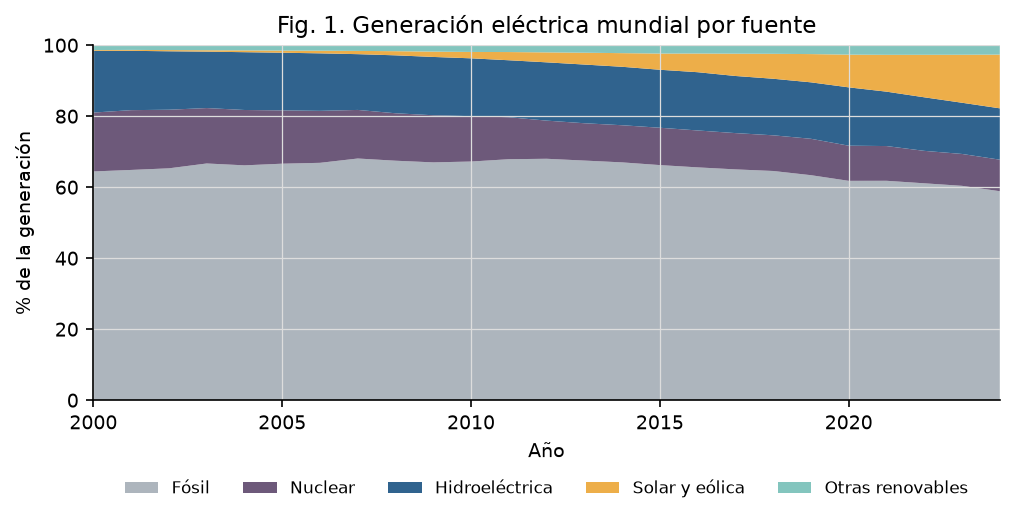

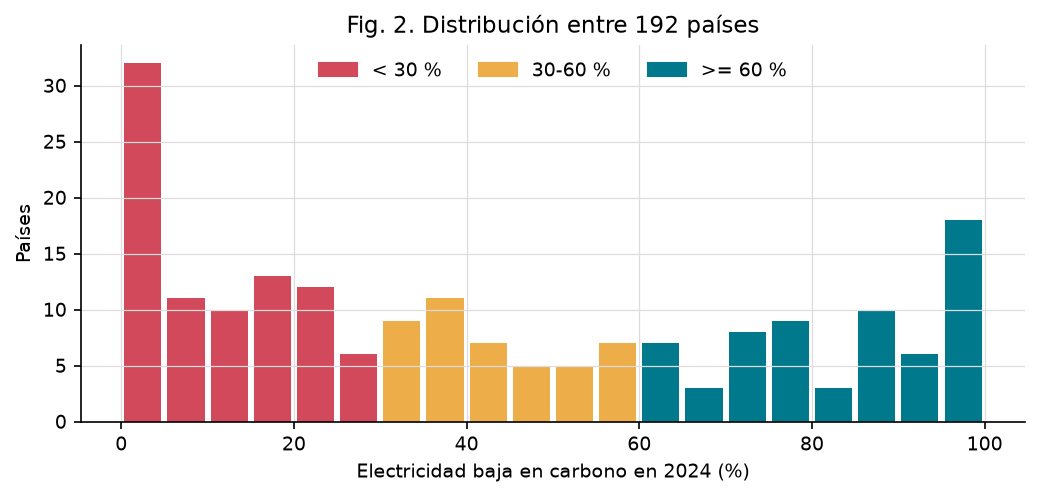

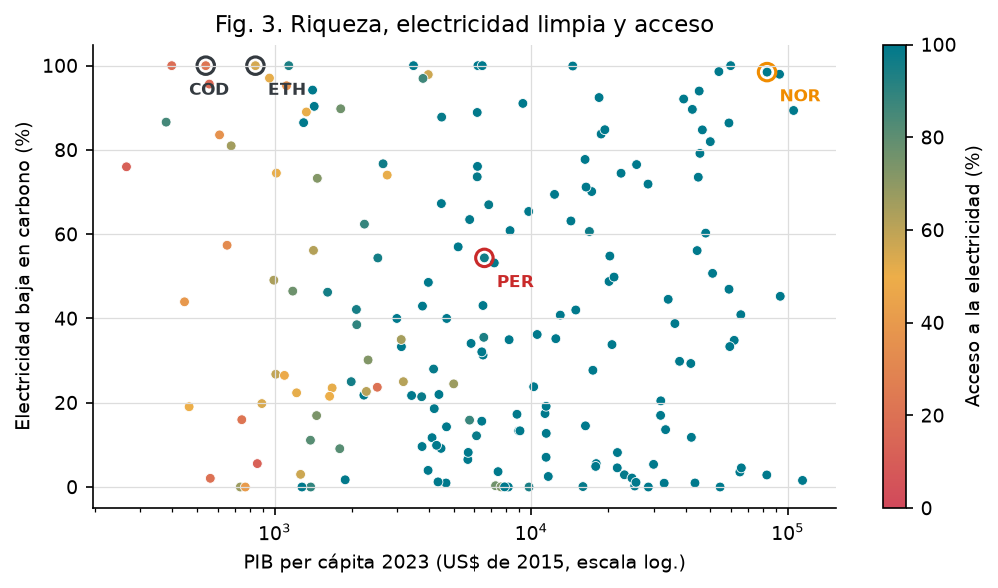

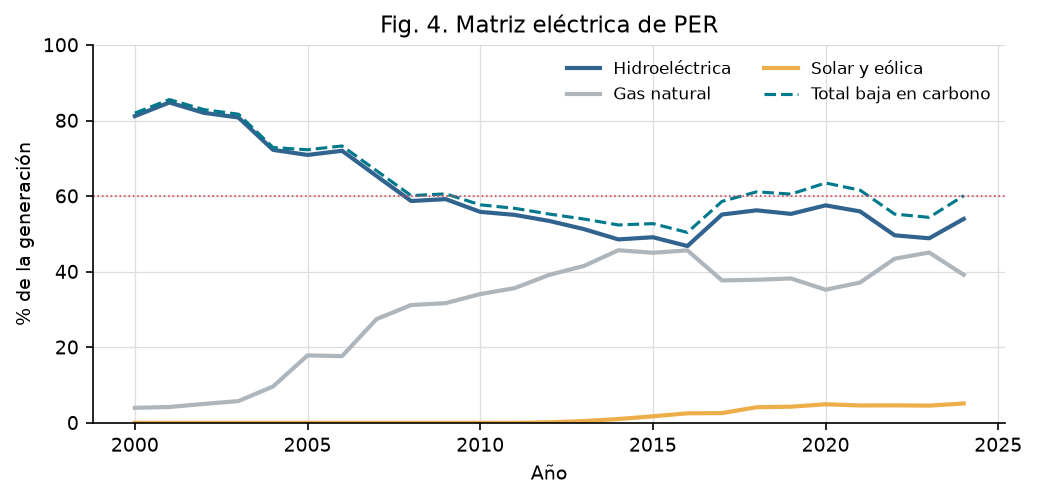

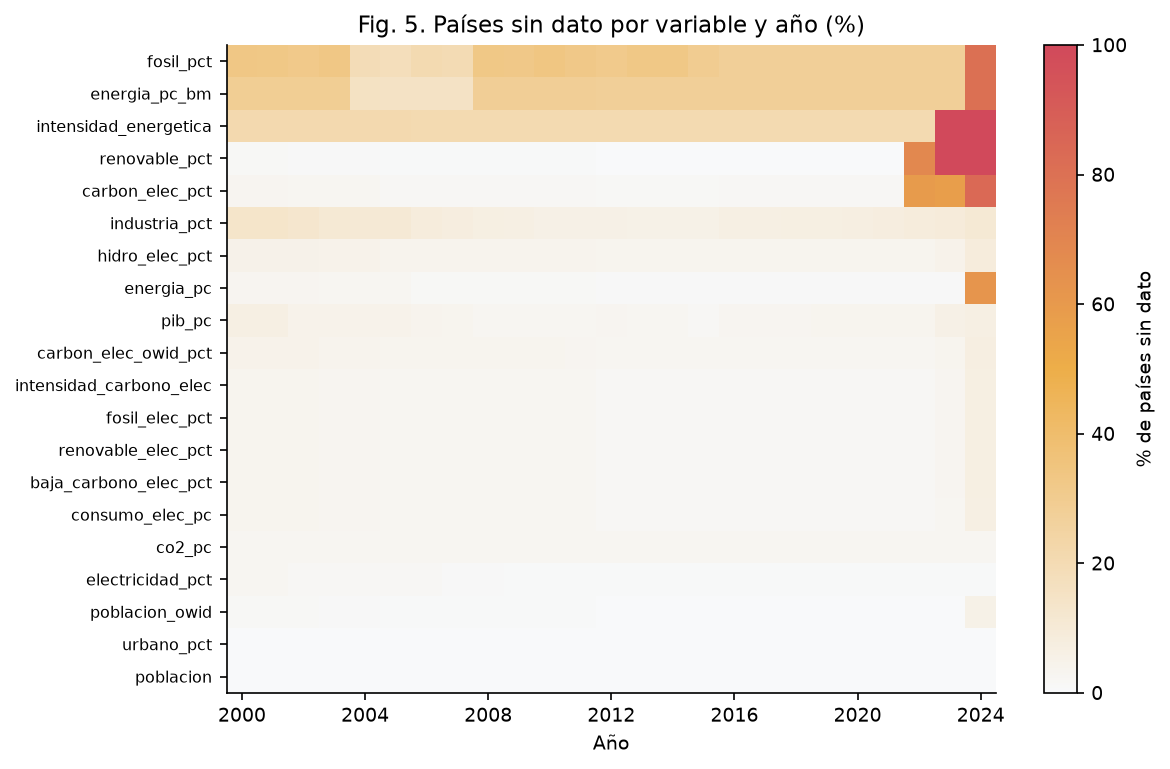

In [18]:
for nombre in ["fig01_matriz_electrica_mundial", "fig02_distribucion_baja_carbono", "fig03_pib_vs_baja_carbono",
               "fig04_matriz_pais_referencia", "fig05_mapa_faltantes"]:
    ruta = CARPETA_FIGURAS / f"{nombre}.png"
    if ruta.exists():
        display(Image(filename=str(ruta), width=720))

## Paso 5. Fase 3 — Preparación de los datos
### 5.1 Selección
Países con la variable de la etiqueta en ≥ 85 % de los años; 2 variables de la etiqueta y 8 covariables. Se descartan las variables con más de 25 % de faltantes y las de la matriz eléctrica, porque revelarían la etiqueta (fuga de información).

In [19]:
# =============================================================================
# PASO 5. FASE 3 - PREPARACIÓN DE LOS DATOS
# =============================================================================
def seleccionar(panel: pd.DataFrame, calidad: pd.DataFrame, resumen: dict, bitacora: list) -> pd.DataFrame:
    """
    SELECCIÓN. Se conservan:
      * los países con la variable base de la etiqueta en >= 85 % de los años (R2),
      * las 2 variables de la etiqueta y 8 covariables. Se descartan las
        variables con > 25 % de faltantes (R3) y las de la matriz eléctrica (fuga).
    """
    cobertura = resumen["cobertura_etiqueta"]
    fuera = sorted(cobertura[cobertura < REQ.cobertura_etiqueta].index)
    retenidos = sorted(cobertura[cobertura >= REQ.cobertura_etiqueta].index)
    muchas_faltas = calidad.loc[calidad["faltantes_pct"] > REQ.max_faltantes_var, "variable"].tolist()
    df = panel.loc[retenidos, ETIQUETA_BASE + COVARIABLES].copy()
    bitacora.append({"paso": "selección", "detalle": f"{len(fuera)} países sin cobertura suficiente de b: {', '.join(fuera)}"})
    bitacora.append({"paso": "selección", "detalle": f"variables con > 25 % de faltantes descartadas: {', '.join(muchas_faltas)}"})
    bitacora.append({"paso": "selección", "detalle": f"variables de la matriz eléctrica excluidas por fuga: {', '.join(FUGA)}"})
    nota(f"{len(retenidos)} países y {df.shape[1]} variables seleccionadas ({len(fuera)} países fuera por cobertura)")
    return df

### 5.2 Limpieza de rangos
Porcentajes fuera de [0, 100] y niveles ≤ 0 se vacían. Se marcan los países con más de 40 % de años vacíos en alguna variable.

In [20]:
def limpiar_rangos(df: pd.DataFrame, bitacora: list) -> tuple[pd.DataFrame, list]:
    """
    LIMPIEZA. Un porcentaje fuera de [0, 100] o un nivel <= 0 no puede ser real:
    se vacía para tratarlo luego como faltante. La industria igual a 0 % (caso de
    Venezuela) también se considera un dato no válido.
    Además se identifican los países con más de 40 % de años vacíos en alguna
    variable: se retirarán porque rellenarlos sería inventar la serie.
    """
    antes = int(df.isna().sum().sum())
    for var in df.columns:
        if es_porcentaje(var):
            df.loc[(df[var] < 0) | (df[var] > 100), var] = np.nan
        else:
            df.loc[df[var] <= 0, var] = np.nan
    df.loc[df["industria_pct"] <= 0, "industria_pct"] = np.nan
    vaciados = int(df.isna().sum().sum()) - antes
    faltas_pais = df.isna().groupby(level="iso3").mean()
    excluir_40 = sorted(faltas_pais[(faltas_pais > REQ.max_faltantes_pais).any(axis=1)].index)
    bitacora.append({"paso": "limpieza", "detalle": f"{vaciados} valores imposibles convertidos en vacío"})
    bitacora.append({"paso": "limpieza", "detalle": f"{len(excluir_40)} países con > 40 % de años vacíos: {', '.join(excluir_40)}"})
    nota(f"{vaciados} valores imposibles vaciados; {len(excluir_40)} países con > 40 % de vacíos marcados")
    return df, excluir_40

### 5.3 Atípicos: filtro de Hampel
Para cada país y variable se compara cada valor con la mediana de una ventana de 5 años centrada en él:

$$|x_{i,t} - m_{i,t}| > 3 \cdot 1{,}4826 \cdot \mathrm{MAD}_{i,t}$$

y además la diferencia debe ser de al menos 10 p.p. (porcentajes) o 20 % (niveles). Los valores de la etiqueta y los de 2009 y 2020 se conservan; el resto se corrige con la mediana móvil.

In [21]:
def filtro_hampel(df: pd.DataFrame, bitacora: list) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """
    ATÍPICOS con el filtro de Hampel, país por país:
        mediana móvil m (5 años centrados) y desviación robusta s = 1,4826 * MAD.
        Un valor x es atípico si |x - m| > 3 s  y además |x - m| >= 10 p.p.
        (porcentajes) o >= 20 % (niveles, analizados en logaritmo).
    Decisión según el caso:
        * 'etiqueta' : valor de la electricidad baja en carbono -> se conserva
                       (un año seco o una central nueva son cambios reales).
        * 'choque'   : ocurre en 2009 o 2020 -> se conserva (crisis y pandemia).
        * 'corregido': cualquier otro -> se reemplaza por la mediana móvil.
    """
    marcados_corregidos = pd.DataFrame(False, index=df.index, columns=df.columns)
    registro = []
    for var in df.columns:
        serie = df[var].unstack()                       # filas = países, columnas = años
        y = serie if es_porcentaje(var) else np.log(serie)
        mediana = y.T.rolling(VENTANA_HAMPEL, center=True, min_periods=VENTANA_HAMPEL).median().T
        mad = (y - mediana).abs().T.rolling(VENTANA_HAMPEL, center=True, min_periods=VENTANA_HAMPEL).median().T
        desvio = (y - mediana).abs()
        minimo = DESVIO_MIN_PCT if es_porcentaje(var) else DESVIO_MIN_NIVEL
        atipico = (desvio > K_HAMPEL * 1.4826 * mad) & (desvio >= minimo)
        for iso, anio in atipico.stack()[lambda s: s].index:
            anio = int(anio)
            tipo = "etiqueta" if var == "baja_carbono_elec_pct" else "choque" if anio in ANIOS_CHOQUE else "corregido"
            reemplazo = mediana.loc[iso, anio] if es_porcentaje(var) else np.exp(mediana.loc[iso, anio])
            registro.append({"iso3": iso, "anio": anio, "variable": var, "valor_original": serie.loc[iso, anio],
                             "mediana_movil": float(reemplazo), "decision": tipo})
    registro = pd.DataFrame(registro, columns=["iso3", "anio", "variable", "valor_original", "mediana_movil", "decision"])
    for r in registro[registro["decision"] == "corregido"].itertuples():
        df.loc[(r.iso3, r.anio), r.variable] = r.mediana_movil
        marcados_corregidos.loc[(r.iso3, r.anio), r.variable] = True
    nota(f"Hampel: {len(registro)} valores marcados; {int((registro['decision'] == 'corregido').sum())} corregidos")
    return df, registro, marcados_corregidos

### 5.4 Imputación
Primero interpolación dentro de cada país (huecos de hasta 3 años, en logaritmo para los niveles); luego, para los porcentajes que siguen vacíos, la mediana del mismo grupo de ingreso y año. Los países que no se pueden completar se retiran.

In [22]:
def _rellenar_serie(serie: pd.Series, en_logaritmo: bool) -> pd.Series:
    """Interpola huecos internos de hasta 3 años y extiende los bordes hasta 3 años."""
    x = np.log(serie) if en_logaritmo else serie.copy()
    x = x.interpolate(limit=MAX_HUECO, limit_area="inside").ffill(limit=MAX_HUECO).bfill(limit=MAX_HUECO)
    return np.exp(x) if en_logaritmo else x


def imputar(df: pd.DataFrame, vacios_iniciales: pd.DataFrame, corregidos: pd.DataFrame,
            excluir_40: list, paises: pd.DataFrame, bitacora: list) -> tuple[pd.DataFrame, pd.DataFrame, list]:
    """
    IMPUTACIÓN en dos pasos:
      1) Dentro de cada país: interpolación (en logaritmo para los niveles).
      2) Porcentajes que siguen vacíos: mediana del mismo grupo de ingreso y año.
    Los países que aún tienen huecos, junto con los marcados por la regla del
    40 %, se retiran. Se devuelve una máscara con cada valor imputado o
    corregido para crear las banderas bandera_imp_*.
    """
    for var in df.columns:
        df[var] = df.groupby(level="iso3")[var].transform(
            lambda s: _rellenar_serie(s.droplevel(0), not es_porcentaje(var)).values)
    n_serie = int((vacios_iniciales & df.notna()).sum().sum())

    ingreso = paises.set_index("iso3")["nivel_ingreso"]
    grupo = df.index.get_level_values("iso3").map(ingreso)
    anios = df.index.get_level_values("anio")
    n_grupo = 0
    for var in [v for v in COVARIABLES if es_porcentaje(v)]:
        mediana = df.groupby([grupo, anios])[var].transform("median")
        llenar = df[var].isna() & mediana.notna()
        n_grupo += int(llenar.sum())
        df.loc[llenar, var] = mediana[llenar]

    imputados = (vacios_iniciales & df.notna()) | corregidos
    con_huecos = df.isna().groupby(level="iso3").sum().sum(axis=1)
    sin_llenar = sorted(set(con_huecos[con_huecos > 0].index) - set(excluir_40))
    retirar = sorted(set(excluir_40) | set(con_huecos[con_huecos > 0].index))
    df = df.drop(index=retirar, level="iso3")
    imputados = imputados.drop(index=retirar, level="iso3")
    bitacora.append({"paso": "imputación", "detalle": f"{n_serie} valores por interpolación dentro del país"})
    bitacora.append({"paso": "imputación", "detalle": f"{n_grupo} valores por mediana del grupo de ingreso y año"})
    bitacora.append({"paso": "imputación", "detalle": f"{len(sin_llenar)} países con huecos que no se pudieron llenar: {', '.join(sin_llenar)}"})
    nota(f"imputados: {n_serie} (interpolación) + {n_grupo} (mediana por ingreso); "
         f"quedan {df.index.get_level_values('iso3').nunique()} países")
    return df, imputados, retirar

### 5.5 Etiqueta
$$\bar b_{i,t} = \frac{b_{i,t-2} + b_{i,t-1} + b_{i,t}}{3}$$

**Avanzada** si $\bar b \ge 60$ y acceso $\ge 90$; **intermedia** si $\bar b \ge 30$; **inicial** si $\bar b < 30$.

In [23]:
def construir_etiqueta(df: pd.DataFrame) -> pd.DataFrame:
    """
    ETIQUETA. b = promedio de 3 años (t-2, t-1, t) de la electricidad baja en
    carbono; luego se aplica asignar_etapa(b, acceso). También se calcula la
    etapa con el valor anual (sin promediar) solo para mostrar cuánto ruido
    evita el promedio.
    """
    df = df.reset_index().sort_values(["iso3", "anio"])
    df["b_promedio_3"] = df.groupby("iso3")["baja_carbono_elec_pct"].transform(lambda s: s.rolling(3).mean())
    df["etapa"] = [asignar_etapa(b, a) for b, a in zip(df["b_promedio_3"], df["electricidad_pct"])]
    df["etapa_anual"] = [asignar_etapa(b, a) for b, a in zip(df["baja_carbono_elec_pct"], df["electricidad_pct"])]
    df["etapa_num"] = df["etapa"].map({"inicial": 0, "intermedia": 1, "avanzada": 2})
    for col in ("etapa", "etapa_anual"):
        previo = df.groupby("iso3")[col].shift()
        df["cambio_" + col] = (df[col] != previo) & previo.notna()
    return df

### 5.6 Predictores del año anterior
Logaritmos de los niveles, variaciones (PIB per cápita, urbanización y energía renovable) y rezago de un año (sufijo `_ant`).

In [24]:
# Predictores base (antes del rezago)
PREDICTORES = ["pib_pc_log", "poblacion_log", "urbano_pct", "industria_pct", "renovable_pct",
               "co2_pc_log", "energia_pc_log", "consumo_elec_pc_log", "var_pib_pc_pct",
               "var_urbano_pp", "var3_renovable_pp"]


def construir_predictores(df: pd.DataFrame) -> tuple[pd.DataFrame, int]:
    """
    TRANSFORMACIÓN.
      * Logaritmo natural de las variables de nivel (PIB, población, CO2, energía):
        reduce la asimetría de variables que van de cientos a cientos de miles.
      * Variación anual del PIB per cápita (%), cambio anual de la urbanización
        (p.p.) y cambio en 3 años de la energía renovable (p.p.).
      * REZAGO de un año (sufijo _ant): la etapa del año t se explica con datos
        de t-1, como ocurriría en la práctica.
    Las filas sin historia suficiente (2000-2003) se retiran.
    """
    g = df.groupby("iso3")
    for var in ["pib_pc", "poblacion", "co2_pc", "energia_pc", "consumo_elec_pc"]:
        df[var + "_log"] = np.log(df[var])
    df["var_pib_pc_pct"] = g["pib_pc"].pct_change() * 100
    df["var_urbano_pp"] = g["urbano_pct"].diff()
    df["var3_renovable_pp"] = g["renovable_pct"].diff(3)
    for var in PREDICTORES:
        df[var + "_ant"] = df.groupby("iso3")[var].shift(1)
    df["anio_relativo"] = df["anio"] - CORTES["entrenamiento"][0]
    antes = len(df)
    df = df.dropna(subset=["etapa"] + [v + "_ant" for v in PREDICTORES]).copy()
    nota(f"predictores: {len(PREDICTORES)} con rezago de un año; {antes - len(df)} filas sin historia retiradas "
         f"(el conjunto empieza en {df['anio'].min()})")
    return df, antes - len(df)

### 5.7 Integración y partición temporal
Nombre del país, región y grupo de ingreso (en español) con sus indicadoras 0/1, banderas `bandera_imp_*` y la columna `conjunto`: 2004–2015 entrenamiento, 2016–2019 validación, 2020–2024 prueba. **No se entrena nada**: solo se rotulan las filas.

In [25]:
def integrar_y_particionar(df: pd.DataFrame, paises: pd.DataFrame, imputados: pd.DataFrame) -> tuple[pd.DataFrame, list]:
    """
    INTEGRACIÓN: nombre del país, región y grupo de ingreso (en español) y sus
    variables indicadoras 0/1; banderas bandera_imp_* (1 = valor imputado o
    corregido). PARTICIÓN temporal: 2004-2015 entrenamiento, 2016-2019
    validación y 2020-2024 prueba. Solo se rotulan las filas.
    """
    meta = paises.set_index("iso3")
    df = df.rename(columns={"iso3": "codigo_iso3"})
    df["nombre_pais"] = df["codigo_iso3"].map(meta["pais"])
    region_en = df["codigo_iso3"].map(meta["region"])
    ingreso_en = df["codigo_iso3"].map(meta["nivel_ingreso"])
    df["region"] = region_en.map(lambda r: REGIONES[r][0])
    df["grupo_ingreso"] = ingreso_en.map(lambda i: INGRESOS[i][0])
    for original, (_, corto) in REGIONES.items():
        df["region_" + corto] = (region_en == original).astype(int)
    for original, (_, corto) in INGRESOS.items():
        df["ingreso_" + corto] = (ingreso_en == original).astype(int)
    banderas = imputados.rename_axis(["codigo_iso3", "anio"]).add_prefix("bandera_imp_").astype(int)
    df = df.merge(banderas.reset_index(), on=["codigo_iso3", "anio"], how="left")
    df["conjunto"] = "prueba"
    for nombre, (a0, a1) in CORTES.items():
        df.loc[df["anio"].between(a0, a1), "conjunto"] = nombre

    identificacion = ["codigo_iso3", "nombre_pais", "region", "grupo_ingreso", "anio"]
    objetivo = ["etapa", "etapa_num"]
    predictores = ([v + "_ant" for v in PREDICTORES] + ["anio_relativo"]
                   + ["region_" + c for _, c in REGIONES.values()] + ["ingreso_" + c for _, c in INGRESOS.values()])
    banderas_cols = ["bandera_imp_" + v for v in COVARIABLES]
    final = df[identificacion + objetivo + predictores + banderas_cols + ["conjunto"]].reset_index(drop=True)
    final["etapa_num"] = final["etapa_num"].astype(int)
    nota(f"conjunto final: {final.shape[0]} filas x {final.shape[1]} columnas")
    return final, predictores, df

### 5.8 Controles de calidad (R1–R10)
Si algún requisito falla, el programa se detiene **antes** de guardar el archivo.

In [26]:
def controles_calidad(final: pd.DataFrame, auditoria: pd.DataFrame, predictores: list,
                      cobertura: pd.Series, calidad: pd.DataFrame) -> pd.DataFrame:
    """
    Verifica los requisitos R1-R10 de la fase 1 sobre el conjunto final.
    Resultado esperado: los 10 controles en 'CUMPLE'. Si alguno falla, el
    programa se detiene ANTES de guardar el archivo (compuerta de calidad).
    """
    numericas = final.select_dtypes("number")
    clases = final["etapa"].value_counts(normalize=True) * 100
    pct_cols = [c for c in predictores if c.endswith("_pct_ant") and not c.startswith("var")]
    prohibidas = FUGA + ETIQUETA_BASE + ["b_promedio_3"]
    fuga = [c for c in final.columns if any(c.startswith(p) for p in prohibidas)]
    recalculada = [asignar_etapa(b, a) for b, a in zip(auditoria["b_promedio_3"], auditoria["electricidad_pct"])]
    cob_final = cobertura.reindex(final["codigo_iso3"].unique()) * 100
    faltas_cov = calidad.set_index("variable").loc[COVARIABLES + ETIQUETA_BASE, "faltantes_pct"]
    n_conj = final["conjunto"].value_counts()
    controles = [
        ("R1", "Países >= 120", final["codigo_iso3"].nunique() >= REQ.min_paises,
         f"{final['codigo_iso3'].nunique()} países"),
        ("R2", "b disponible en >= 85 % de los años", bool((cob_final >= REQ.cobertura_etiqueta * 100).all()),
         f"mínimo {cob_final.min():.1f} % de los años"),
        ("R3", "Variables con <= 25 % de faltantes", bool((faltas_cov <= REQ.max_faltantes_var).all()),
         f"máximo {faltas_cov.max():.1f} % ({faltas_cov.idxmax()})"),
        ("R4", "Sin nulos ni infinitos", final.isna().sum().sum() == 0 and not np.isinf(numericas.values).any(), "0 y 0"),
        ("R5", "Una fila por país-año, sin saltos",
         (not final.duplicated(["codigo_iso3", "anio"]).any())
         and final.groupby("codigo_iso3")["anio"].apply(lambda s: (s.diff().dropna() == 1).all()).all(), "cumple"),
        ("R6", "Porcentajes en [0, 100]", all(final[c].between(0, 100).all() for c in pct_cols), f"{len(pct_cols)} variables"),
        ("R7", "Cada etapa >= 10 % de las filas", clases.min() >= REQ.min_clase, f"mínimo {clases.min():.1f} %"),
        ("R8", "Sin componentes de la etiqueta; predictores del año anterior",
         not fuga and all(c.endswith("_ant") for c in predictores[:len(PREDICTORES)]), "cumple"),
        ("R9", "La etiqueta se reproduce al recalcularla",
         all(r == e for r, e in zip(recalculada, auditoria["etapa"])), "100 % de coincidencia"),
        ("R10", "Tres etapas en cada conjunto",
         all(final.loc[final["conjunto"] == c, "etapa"].nunique() == 3 for c in CORTES),
         " / ".join(str(n_conj.get(c, 0)) for c in CORTES) + " filas"),
    ]
    tabla = pd.DataFrame(controles, columns=["codigo", "requisito", "cumple", "detalle"])
    tabla["cumple"] = tabla["cumple"].map(lambda v: "CUMPLE" if v else "NO CUMPLE")
    tabla.to_csv(CARPETA_REPORTES / "fase3_controles_calidad.csv", index=False)
    for c in tabla.itertuples():
        nota(f"{c.codigo:<4} {c.cumple:<10} {c.requisito} ({c.detalle})")
    if (tabla["cumple"] != "CUMPLE").any():
        sys.exit("Algún requisito de calidad falló: el conjunto NO se guardó.")
    return tabla

### 5.9 Figuras, diccionario de datos y ejecución de la fase 3

In [27]:
def graficos_preparacion(auditoria: pd.DataFrame, final: pd.DataFrame) -> None:
    """Figuras 6 a 8 de la preparación de los datos."""
    # Figura 6: por qué se promedia b en 3 años (ejemplo: Letonia)
    e = auditoria[auditoria["codigo_iso3"] == "LVA"].set_index("anio")
    if not e.empty:
        fig, (ax, ax2) = plt.subplots(2, 1, figsize=(7, 4), sharex=True, gridspec_kw={"height_ratios": [4, 1.2]})
        ax.plot(e.index, e["baja_carbono_elec_pct"], color=GRIS, marker="o", ms=3, label="Valor anual")
        ax.plot(e.index, e["b_promedio_3"], color=COLOR_ETAPA["avanzada"], lw=2, label="Promedio de 3 años")
        ax.axhline(REQ.umbral_avanzada, color=COLOR_ETAPA["inicial"], ls=":", lw=1)
        ax.set(ylabel="Elec. baja en carbono (%)", title="Fig. 6. Letonia: la etapa anual cambia mucho más que la suavizada")
        ax.legend(frameon=False, ncol=2)
        for k, col in enumerate(["etapa_anual", "etapa"]):
            for anio, etapa in e[col].items():
                ax2.barh(1 - k, 1, left=anio - 0.5, color=COLOR_ETAPA[etapa], height=0.8)
        ax2.set_yticks([1, 0], ["Anual", "Suavizada"])
        ax2.grid(False)
        ax2.set_xticks(range(CORTES["entrenamiento"][0], ANIO_FIN + 1, 4))
        ax2.set_xlabel("Año")
        guardar_figura(fig, "fig06_suavizado_etiqueta.png")

    # Figura 7: matriz de transición entre el primer y el último año
    orden = ["inicial", "intermedia", "avanzada"]
    a0, a1 = final["anio"].min(), final["anio"].max()
    tm = pd.crosstab(final[final["anio"] == a0].set_index("codigo_iso3")["etapa"],
                     final[final["anio"] == a1].set_index("codigo_iso3")["etapa"]).reindex(index=orden, columns=orden).fillna(0).astype(int)
    tm.to_csv(CARPETA_REPORTES / f"fase3_transiciones_{a0}_{a1}.csv")
    fig, ax = plt.subplots(figsize=(4.8, 4))
    ax.imshow(tm.values, cmap=LinearSegmentedColormap.from_list("t", ["#f8f9fa", COLOR_ETAPA["avanzada"]]))
    for i in range(3):
        for j in range(3):
            ax.text(j, i, tm.values[i, j], ha="center", va="center", fontsize=12,
                    color="white" if tm.values[i, j] > 40 else "black")
    ax.set_xticks(range(3), [o.capitalize() for o in orden])
    ax.set_yticks(range(3), [o.capitalize() for o in orden])
    ax.grid(False)
    ax.set(xlabel=f"Etapa en {a1}", ylabel=f"Etapa en {a0}", title="Fig. 7. Transiciones entre etapas")
    guardar_figura(fig, "fig07_matriz_transicion.png")

    # Figura 8: proporción de etapas por año y conjuntos
    pc = final.groupby("anio")["etapa"].value_counts(normalize=True).unstack().reindex(columns=orden).fillna(0) * 100
    fig, ax = plt.subplots(figsize=(7, 3.6))
    base = np.zeros(len(pc))
    for etapa in orden:
        ax.bar(pc.index, pc[etapa], bottom=base, color=COLOR_ETAPA[etapa], label=etapa.capitalize(), width=0.85)
        base += pc[etapa].values
    for nombre, (x0, x1) in CORTES.items():
        ax.annotate("", xy=(x0 - 0.45, 104), xytext=(x1 + 0.45, 104), arrowprops=dict(arrowstyle="|-|", lw=0.8))
        ax.text((x0 + x1) / 2, 107, {"validacion": "Validación"}.get(nombre, nombre.capitalize()), ha="center", fontsize=8)
    ax.set(ylim=(0, 118), xlabel="Año", ylabel="% de países", title="Fig. 8. Etapas por año y partición temporal")
    ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.18))
    guardar_figura(fig, "fig08_etapas_por_anio.png")


def diccionario_datos(final: pd.DataFrame) -> pd.DataFrame:
    """Describe cada columna del conjunto final (tipo, papel y significado)."""
    filas = []
    for col in final.columns:
        base = col.removesuffix("_ant").removesuffix("_log").replace("bandera_imp_", "")
        if col in ("etapa", "etapa_num"):
            papel, texto = "objetivo", "Etapa de transición (0 inicial, 1 intermedia, 2 avanzada)"
        elif col.startswith("bandera_imp_"):
            papel, texto = "bandera", f"1 si {base} fue imputada o corregida en el año t"
        elif col.endswith("_ant"):
            papel = "predictor"
            texto = {"var_pib_pc_pct": "Variación anual del PIB per cápita (%)",
                     "var_urbano_pp": "Cambio anual de la población urbana (p.p.)",
                     "var3_renovable_pp": "Cambio en 3 años de la energía renovable (p.p.)"}.get(base, DESCRIPCION.get(base, base))
            texto += (" (logaritmo)" if "_log" in col else "") + ", año anterior"
        elif col.startswith(("region_", "ingreso_")):
            papel, texto = "predictor", "Indicadora 0/1 de " + col.replace("_", " ")
        elif col == "anio_relativo":
            papel, texto = "predictor", "Años transcurridos desde 2004"
        elif col == "conjunto":
            papel, texto = "partición", "entrenamiento (2004-2015), validacion (2016-2019), prueba (2020-2024)"
        else:
            papel, texto = "identificación", {"codigo_iso3": "Código ISO de 3 letras", "nombre_pais": "Nombre del país",
                                              "region": "Región del Banco Mundial", "grupo_ingreso": "Grupo de ingreso del Banco Mundial",
                                              "anio": "Año"}[col]
        filas.append({"columna": col, "tipo": str(final[col].dtype), "papel": papel, "descripcion": texto})
    dic = pd.DataFrame(filas)
    dic.to_csv(CARPETA_PREPARADOS / "diccionario_datos.csv", index=False)
    return dic

**Resultado esperado:** `datos/preparados/etapas_transicion_preparado.csv` con 3 780 filas × 39 columnas, 180 países (2004–2024), sin faltantes; etapas 49,7 % inicial, 33,8 % intermedia y 16,5 % avanzada; los diez requisitos en *CUMPLE*.

In [28]:
def fase3_preparacion_datos(fase2: dict) -> pd.DataFrame:
    """
    Convierte el panel crudo en el conjunto etiquetado listo para modelar.

    Resultado esperado:
      * datos/preparados/etapas_transicion_preparado.csv: 3 780 filas x 39
        columnas, 180 países, 2004-2024, sin faltantes (49,7 % inicial,
        33,8 % intermedia, 16,5 % avanzada).
      * datos/preparados/etapas_auditoria.csv y diccionario_datos.csv.
      * resultados/reportes/fase3_*.csv, fase3_preparacion.md.
      * resultados/figuras/fig06 a fig08.
    """
    seccion("FASE 3 - PREPARACIÓN DE LOS DATOS")
    bitacora = []
    df = seleccionar(fase2["panel"], fase2["calidad"], fase2["resumen"], bitacora)
    df, excluir_40 = limpiar_rangos(df, bitacora)
    vacios = df.isna()
    df, atipicos, corregidos = filtro_hampel(df, bitacora)
    df, imputados, retirados = imputar(df, vacios, corregidos, excluir_40, fase2["paises"], bitacora)

    atipicos = atipicos[~atipicos["iso3"].isin(retirados)]
    atipicos.to_csv(CARPETA_REPORTES / "fase3_atipicos_hampel.csv", index=False)
    resumen_at = atipicos.groupby(["variable", "decision"]).size().unstack(fill_value=0)
    bitacora.append({"paso": "atípicos", "detalle": "Hampel en países retenidos: "
                     + ", ".join(f"{k} {v}" for k, v in atipicos["decision"].value_counts().items())})

    df = construir_etiqueta(df)
    df, sin_historia = construir_predictores(df)
    bitacora.append({"paso": "transformación", "detalle": f"{sin_historia} filas de 2000-2003 sin historia retiradas"})
    final, predictores, auditoria = integrar_y_particionar(df, fase2["paises"], imputados)
    controles = controles_calidad(final, auditoria, predictores, fase2["resumen"]["cobertura_etiqueta"], fase2["calidad"])

    # Solo si los controles pasan, se guardan los archivos
    final.to_csv(CARPETA_PREPARADOS / "etapas_transicion_preparado.csv", index=False)
    auditoria.to_csv(CARPETA_PREPARADOS / "etapas_auditoria.csv", index=False)
    diccionario_datos(final)
    pd.DataFrame(bitacora).to_csv(CARPETA_REPORTES / "fase3_bitacora.csv", index=False)
    graficos_preparacion(auditoria, final)

    clases = final["etapa"].value_counts()
    cambios = auditoria[auditoria["anio"] > auditoria["anio"].min()]
    md = ["# Fase 3 - Preparación de los datos", "",
          f"* Filas: {final.shape[0]}; columnas: {final.shape[1]}; países: {final['codigo_iso3'].nunique()}; "
          f"años: {final['anio'].min()}-{final['anio'].max()}.",
          "* Etapas: " + ", ".join(f"{k} {v} ({v / len(final) * 100:.1f} %)" for k, v in clases.items()) + ".",
          "* Filas por conjunto: " + ", ".join(f"{k} {v}" for k, v in final["conjunto"].value_counts().items()) + ".",
          f"* Cambios de etapa: {int(cambios['cambio_etapa_anual'].sum())} con el valor anual y "
          f"{int(cambios['cambio_etapa'].sum())} con el promedio de 3 años.",
          "", "## Bitácora", "", tabla_md(pd.DataFrame(bitacora)), "",
          "## Atípicos (filtro de Hampel)", "", tabla_md(resumen_at.reset_index()), "",
          "## Controles de calidad", "", tabla_md(controles), ""]
    (CARPETA_REPORTES / "fase3_preparacion.md").write_text("\n".join(md), encoding="utf-8")
    nota("conjunto guardado en datos/preparados/etapas_transicion_preparado.csv")
    return final

In [29]:
final = fase3_preparacion_datos(fase2)


 FASE 3 - PREPARACIÓN DE LOS DATOS
   - 200 países y 10 variables seleccionadas (6 países fuera por cobertura)
   - 39 valores imposibles vaciados; 15 países con > 40 % de vacíos marcados


   - Hampel: 111 valores marcados; 64 corregidos


   - imputados: 823 (interpolación) + 299 (mediana por ingreso); quedan 180 países
   - predictores: 11 con rezago de un año; 720 filas sin historia retiradas (el conjunto empieza en 2004)
   - conjunto final: 3780 filas x 39 columnas
   - R1   CUMPLE     Países >= 120 (180 países)
   - R2   CUMPLE     b disponible en >= 85 % de los años (mínimo 88.0 % de los años)
   - R3   CUMPLE     Variables con <= 25 % de faltantes (máximo 11.1 % (renovable_pct))
   - R4   CUMPLE     Sin nulos ni infinitos (0 y 0)
   - R5   CUMPLE     Una fila por país-año, sin saltos (cumple)
   - R6   CUMPLE     Porcentajes en [0, 100] (3 variables)
   - R7   CUMPLE     Cada etapa >= 10 % de las filas (mínimo 16.5 %)
   - R8   CUMPLE     Sin componentes de la etiqueta; predictores del año anterior (cumple)
   - R9   CUMPLE     La etiqueta se reproduce al recalcularla (100 % de coincidencia)
   - R10  CUMPLE     Tres etapas en cada conjunto (2160 / 720 / 900 filas)


   - figura guardada: resultados/figuras/fig06_suavizado_etiqueta.png
   - figura guardada: resultados/figuras/fig07_matriz_transicion.png


   - figura guardada: resultados/figuras/fig08_etapas_por_anio.png
   - conjunto guardado en datos/preparados/etapas_transicion_preparado.csv


**Controles de calidad:**

In [30]:
pd.read_csv(CARPETA_REPORTES / "fase3_controles_calidad.csv")

,codigo,requisito,cumple,detalle
0,R1,Países >= 120,CUMPLE,180 países
1,R2,b disponible en >= 85 % de los años,CUMPLE,mínimo 88.0 % de los años
2,R3,Variables con <= 25 % de faltantes,CUMPLE,máximo 11.1 % (renovable_pct)
3,R4,Sin nulos ni infinitos,CUMPLE,0 y 0
4,R5,"Una fila por país-año, sin saltos",CUMPLE,cumple
5,R6,"Porcentajes en [0, 100]",CUMPLE,3 variables
6,R7,Cada etapa >= 10 % de las filas,CUMPLE,mínimo 16.5 %
7,R8,Sin componentes de la etiqueta; predictores de...,CUMPLE,cumple
8,R9,La etiqueta se reproduce al recalcularla,CUMPLE,100 % de coincidencia
9,R10,Tres etapas en cada conjunto,CUMPLE,2160 / 720 / 900 filas


**Bitácora de la preparación:**

In [31]:
with pd.option_context("display.max_colwidth", 200):
    display(pd.read_csv(CARPETA_REPORTES / "fase3_bitacora.csv"))

,paso,detalle
0,selección,"6 países sin cobertura suficiente de b: CUW, FSM, MNE, MNP, SSD, TUV"
1,selección,"variables con > 25 % de faltantes descartadas: energia_pc_bm, fosil_pct, intensidad_energetica"
2,selección,"variables de la matriz eléctrica excluidas por fuga: renovable_elec_pct, fosil_elec_pct, hidro_elec_pct, carbon_elec_owid_pct, intensidad_carbono_elec, carbon_elec_pct"
3,limpieza,39 valores imposibles convertidos en vacío
4,limpieza,"15 países con > 40 % de años vacíos: ARM, ASM, DJI, ERI, GIB, GUM, NCL, NRU, PRK, PSE, SOM, SRB, VEN, VGB, VIR"
5,imputación,823 valores por interpolación dentro del país
6,imputación,299 valores por mediana del grupo de ingreso y año
7,imputación,"5 países con huecos que no se pudieron llenar: CYM, FRO, LBR, TCA, YEM"
8,atípicos,"Hampel en países retenidos: corregido 49, choque 24, etiqueta 18"
9,transformación,720 filas de 2000-2003 sin historia retiradas


**Atípicos detectados por el filtro de Hampel (resumen):**

In [32]:
atipicos = pd.read_csv(CARPETA_REPORTES / "fase3_atipicos_hampel.csv", keep_default_na=False, na_values=[""])
atipicos.groupby(["variable", "decision"]).size().unstack(fill_value=0)

decision,choque,corregido,etiqueta
variable,,,
baja_carbono_elec_pct,0,0,18
co2_pc,9,10,0
consumo_elec_pc,3,24,0
electricidad_pct,0,3,0
energia_pc,2,10,0
industria_pct,3,1,0
pib_pc,7,1,0


**Vista previa del conjunto preparado:**

In [33]:
final.head(10)

,codigo_iso3,nombre_pais,region,grupo_ingreso,anio,etapa,etapa_num,pib_pc_log_ant,poblacion_log_ant,urbano_pct_ant,...,ingreso_bajo,bandera_imp_pib_pc,bandera_imp_poblacion,bandera_imp_urbano_pct,bandera_imp_industria_pct,bandera_imp_renovable_pct,bandera_imp_co2_pc,bandera_imp_energia_pc,bandera_imp_consumo_elec_pc,conjunto
0,ABW,Aruba,América Latina y el Caribe,Ingreso alto,2004,inicial,0,10.258564,11.441730,65.198292,...,0,0,0,0,0,0,0,0,0,entrenamiento
1,ABW,Aruba,América Latina y el Caribe,Ingreso alto,2005,inicial,0,10.307611,11.463084,65.088653,...,0,0,0,0,0,0,0,0,0,entrenamiento
2,ABW,Aruba,América Latina y el Caribe,Ingreso alto,2006,inicial,0,10.277865,11.488991,64.958023,...,0,0,0,0,0,0,0,0,0,entrenamiento
3,ABW,Aruba,América Latina y el Caribe,Ingreso alto,2007,inicial,0,10.271109,11.506958,64.811270,...,0,0,0,0,0,0,0,0,0,entrenamiento
4,ABW,Aruba,América Latina y el Caribe,Ingreso alto,2008,inicial,0,10.294070,11.514424,64.653266,...,0,0,0,0,0,0,0,0,0,entrenamiento
5,ABW,Aruba,América Latina y el Caribe,Ingreso alto,2009,inicial,0,10.304632,11.522054,64.488881,...,0,0,0,0,0,0,0,0,0,entrenamiento
6,ABW,Aruba,América Latina y el Caribe,Ingreso alto,2010,inicial,0,10.173670,11.528838,64.322985,...,0,0,0,0,0,0,0,0,0,entrenamiento
7,ABW,Aruba,América Latina y el Caribe,Ingreso alto,2011,inicial,0,10.143654,11.531139,64.161297,...,0,0,0,0,0,0,1,1,0,entrenamiento
8,ABW,Aruba,América Latina y el Caribe,Ingreso alto,2012,inicial,0,10.169424,11.538505,63.999261,...,0,0,0,0,0,0,0,0,0,entrenamiento
9,ABW,Aruba,América Latina y el Caribe,Ingreso alto,2013,inicial,0,10.144264,11.553203,63.825209,...,0,0,0,0,0,0,0,0,0,entrenamiento


**Distribución de etapas por conjunto (%):**

In [34]:
(pd.crosstab(final["conjunto"], final["etapa"], normalize="index") * 100).round(1)

etapa,avanzada,inicial,intermedia
conjunto,,,
entrenamiento,12.9,51.1,36.0
prueba,22.9,46.3,30.8
validacion,19.0,50.0,31.0


**Diccionario de datos:**

In [35]:
with pd.option_context("display.max_rows", 60, "display.max_colwidth", 100):
    display(pd.read_csv(CARPETA_PREPARADOS / "diccionario_datos.csv"))

,columna,tipo,papel,descripcion
0,codigo_iso3,str,identificación,Código ISO de 3 letras
1,nombre_pais,str,identificación,Nombre del país
2,region,str,identificación,Región del Banco Mundial
3,grupo_ingreso,str,identificación,Grupo de ingreso del Banco Mundial
4,anio,int64,identificación,Año
5,etapa,str,objetivo,"Etapa de transición (0 inicial, 1 intermedia, 2 avanzada)"
6,etapa_num,int64,objetivo,"Etapa de transición (0 inicial, 1 intermedia, 2 avanzada)"
7,pib_pc_log_ant,float64,predictor,"PIB per cápita (US$ constantes de 2015) (logaritmo), año anterior"
8,poblacion_log_ant,float64,predictor,"Población total (habitantes) (logaritmo), año anterior"
9,urbano_pct_ant,float64,predictor,"Población urbana (% del total), año anterior"


**Figuras de la preparación:**

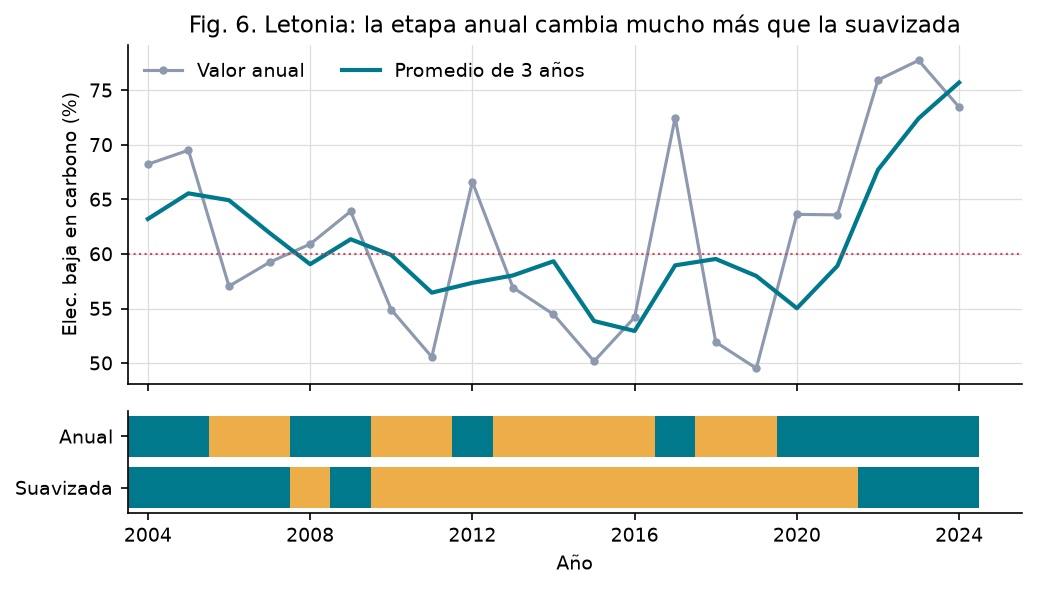

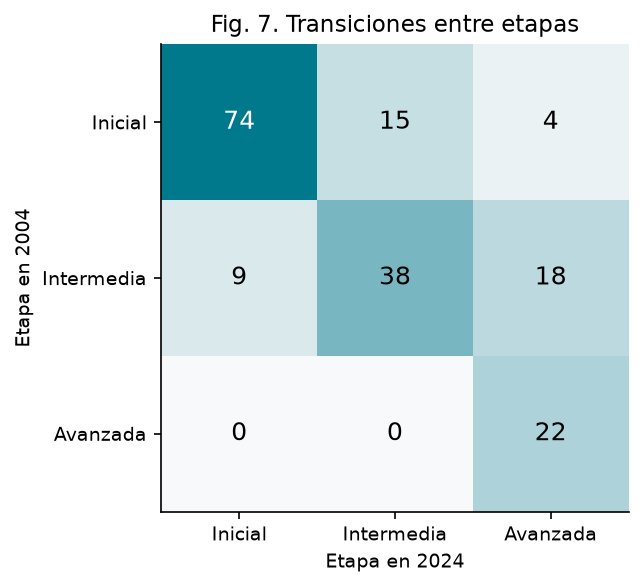

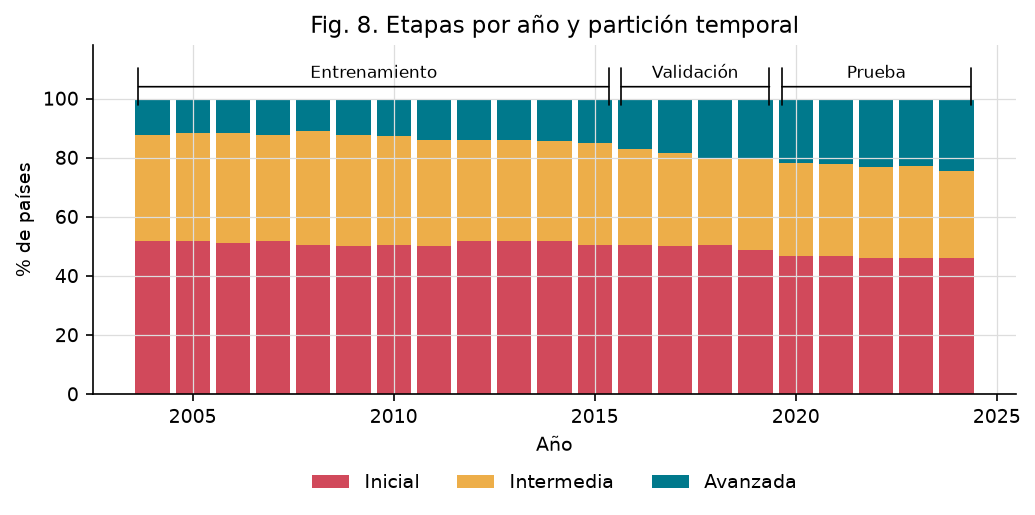

In [36]:
for nombre in ["fig06_suavizado_etiqueta", "fig07_matriz_transicion", "fig08_etapas_por_anio"]:
    display(Image(filename=str(CARPETA_FIGURAS / f"{nombre}.png"), width=720))

## Paso 6. Resumen
Equivale al bloque final de `principal()` en `main.py`.

In [37]:
seccion("RESUMEN")
nota(f"conjunto listo para modelar: {final.shape[0]} filas, {final.shape[1]} columnas, "
     f"{final['codigo_iso3'].nunique()} países")
nota("fase de modelado: NO incluida (según las indicaciones del curso)")


 RESUMEN
   - conjunto listo para modelar: 3780 filas, 39 columnas, 180 países
   - fase de modelado: NO incluida (según las indicaciones del curso)


---
**Archivos generados** (los mismos que produce `main.py`):
- `datos/crudos/` — copia local de los datos del Banco Mundial y de OWID
- `datos/preparados/etapas_transicion_preparado.csv` — conjunto final listo para modelar
- `datos/preparados/etapas_auditoria.csv` — tabla con los insumos de la etiqueta (para verificar R9)
- `datos/preparados/diccionario_datos.csv` — descripción de cada columna
- `resultados/reportes/` — reportes de las fases 1, 2 y 3 (Markdown, JSON y CSV)
- `resultados/figuras/` — figuras 1 a 8